# Ambang adaptif Pan-Tompkins

Notebook ini menurunkan, membuktikan, dan mengukur tahap ambang adaptif Pan-Tompkins
halaman 233 sampai 234: persamaan (12) sampai (23). Tahap ini mengubah selubung energi keluaran
integrator jendela bergerak menjadi keputusan biner QRS atau bukan QRS.

$$ SPKI = 0{,}125 \, PEAKI + 0{,}875 \, SPKI \quad \text{bila PEAKI adalah puncak sinyal} $$

$$ NPKI = 0{,}125 \, PEAKI + 0{,}875 \, NPKI \quad \text{bila PEAKI adalah puncak derau} $$

$$ THRESHOLD_{I1} = NPKI + 0{,}25 \left( SPKI - NPKI \right) $$

$$ THRESHOLD_{I2} = 0{,}5 \, THRESHOLD_{I1} $$

$$ SPKI = 0{,}25 \, PEAKI + 0{,}75 \, SPKI \quad \text{bila QRS ditemukan lewat ambang kedua} $$

Setiap angka yang diklaim dihitung di sel tempat angka itu dicetak. Notebook ini adalah pasangan
`five-point-derivative-equation.ipynb` dan `squaring-and-moving-window-integrator-equation.ipynb`,
dan tahap masukannya adalah selubung energi persamaan (11) halaman 233.

Isi notebook:

1. Sumber halaman 233 dan 234 dan notasi seluruh variabel.
2. Peran tiap ambang dan mengapa ada dua domain, domain integrasi dan domain EKG terfilter.
3. Lima bentuk tetap persamaan (12) sampai (23) dan bukti bebas pengali.
4. Pembaruan SPKI dan NPKI sebagai integrator bocor, beserta konstanta waktunya dalam jumlah denyut.
5. Galat per langkah dan galat kumulatif pembaruan bulat lawan acuan pecahan, dan dua mode pembulatan.
6. Tabel hitung tangan jejak ambang untuk deret puncak buatan.
7. Akibat pemotongan separuh ambang persamaan (22) dan (23) pada irama teratur buatan.
8. Catatan fixed-point memakai konvensi terkunci.
9. Tiga keputusan terkunci 19 Oktober 2026, yaitu inisialisasi P3-1, tetapan kriteria irama tidak
   teratur P3-3, dan aturan kedua domain P3-5, beserta pengukurannya pada rekaman uji.
10. Pengukuran jalur search back pada rekaman nyata AFDB `04015`.
11. Ringkasan seluruh angka terukur.


## 1. Sumber halaman 233 dan 234

Halaman 233 memuat kalimat pembuka tahap ini, dan halaman 234 memuat persamaan (16) sampai (23).
Kutipan di bawah disalin langsung dari gambar halaman 600 dpi, bukan dari hasil ekstraksi teks,
karena lapisan teks halaman ini rusak. Halaman yang dibaca adalah halaman berkas PDF keempat dan
kelima, yang berkorespondensi dengan halaman jurnal 233 dan 234.

Kalimat kunci dari halaman 233:

1. "The higher of the two thresholds in each of the two sets is used for the first analysis of the
   signal. The lower threshold is used if no QRS is detected in a certain time interval so that a
   search-back technique is necessary to look back in time for the QRS complex."
2. "The set of thresholds initially applied to the integration waveform is computed from", lalu
   persamaan (12), (13), (14), dan (15).
3. "where all the variables refer to the integration waveform: PEAKI is the overall peak, SPKI is the
   running estimate of the signal peak, NPKI is the running estimate of the noise peak, THRESHOLD I1
   is the first threshold applied, and THRESHOLD I2 is the second threshold applied."
4. "A peak is a local maximum determined by observing when the signal changes direction within a
   predefined time interval. The signal peak SPKI is a peak that the algorithm has already
   established to be a QRS complex. The noise peak NPKI is any peak".

Kalimat kunci dari halaman 234:

5. Sambungan kalimat nomor 4: "that is not related to the QRS (e.g., the T wave). The thresholds are
   based upon running estimates of SPKI and NPKI. That is, new values of these variables are computed
   in part from their prior values. When a new peak is detected, it must first be classified as a
   noise peak or a signal peak. To be a signal peak, the peak must exceed THRESHOLD I1 as the signal
   is first analyzed or THRESHOLD I2 if searchback is required to find the QRS."
6. "When the QRS complex is found using the second threshold," lalu persamaan (16).
7. "The set of thresholds applied to the filtered ECG is determined from", lalu persamaan (17)
   sampai (20), disusul definisi PEAKF, SPKF, NPKF, THRESHOLD F1, dan THRESHOLD F2, lalu persamaan
   (21) untuk domain kedua.
8. "For irregular heart rates, the first threshold of each set is reduced by half so as to increase
   the detection sensitivity and to avoid missing beats:", lalu persamaan (22) dan (23).
9. "To be identified as a QRS complex, a peak must be recognized as such a complex in both the
   integration and bandpass-filtered waveforms."

Kalimat nomor 5 adalah kalimat terpenting untuk implementasi. Bunyinya menetapkan bahwa setiap
puncak baru hanya memutakhirkan salah satu dari SPKI atau NPKI, bukan keduanya, karena puncak itu
diklasifikasikan lebih dulu sebagai puncak derau atau puncak sinyal. Kualifikasi pada persamaan (12)
dan (13) menegaskan hal yang sama: persamaan (12) berlaku "if PEAKI is the signal peak" dan
persamaan (13) berlaku "if PEAKI is the noise peak". Dua kualifikasi itu saling meniadakan, jadi
satu puncak tidak pernah masuk ke kedua persamaan sekaligus.


## 2. Notasi

| Simbol | Arti | Keterangan |
|---|---|---|
| $n$ | indeks puncak, bukan indeks sampel | satu puncak per pembaruan, $n \geq 1$ |
| $PEAKI$ | puncak yang sedang diklasifikasikan | nilai absolut maksimum lokal pada selubung integrasi |
| $SPKI$ | taksiran berjalan puncak sinyal | diperbarui hanya bila puncaknya puncak sinyal |
| $NPKI$ | taksiran berjalan puncak derau | diperbarui hanya bila puncaknya puncak derau |
| $THRESHOLD_{I1}$ | ambang pertama domain integrasi | dipakai pada analisis pertama sinyal |
| $THRESHOLD_{I2}$ | ambang kedua domain integrasi | dipakai pada pencarian mundur, search back |
| $PEAKF$ | puncak domain EKG terfilter | kualifikasi sama seperti PEAKI |
| $SPKF$ | taksiran berjalan puncak sinyal domain EKG terfilter | persamaan (17) |
| $NPKF$ | taksiran berjalan puncak derau domain EKG terfilter | persamaan (18) |
| $THRESHOLD_{F1}$ | ambang pertama domain EKG terfilter | persamaan (19) |
| $THRESHOLD_{F2}$ | ambang kedua domain EKG terfilter | persamaan (20) |
| $\alpha$ | bobot pembaruan puncak sinyal | $\alpha = 0{,}125$ pada persamaan (12) dan (17) |
| $\beta$ | bobot pembaruan puncak sinyal lewat ambang kedua | $\beta = 0{,}25$ pada persamaan (16) dan (21) |
| $\tau$ | konstanta waktu pembaruan | dalam jumlah pemutakhiran, yaitu denyut |
| $RR$ | jarak antar dua QRS berurutan | satuan detik |
| $RR\,AVERAGE2$ | rata-rata delapan RR terpilih | dipakai untuk $RR\,MISSED\,LIMIT$ |

Angka-angka penting ditulis tebal: **0,125** adalah bobot masuknya puncak baru pada persamaan (12),
(13), (17), dan (18), **0,875** adalah bobot nilai lamanya, **0,5** adalah rasio ambang kedua
terhadap ambang pertama, dan **0,25** adalah dua peran berbeda yang harus dibedakan, yaitu bobot
selisih pada persamaan (14) dan (19) serta bobot puncak baru pada persamaan (16) dan (21).

Satu catatan istilah: makalah menulis indeks $I$ untuk integration, yaitu selubung energi keluaran
jendela bergerak, dan indeks $F$ untuk filtered, yaitu EKG sesudah bandpass. Dokumen ini memakai
istilah domain integrasi dan domain EKG terfilter.

Nilai awal kedua taksiran, $SPKI_0$ dan $NPKI_0$, ditetapkan oleh keputusan terkunci P3-1 sebagai
maksimum dua detik pertama sinyal pada masing masing domain, bukan nol. Nilai awal itu dibahas dan
diukur di bagian 10.


## 3. Peran tiap ambang dan mengapa ada dua domain

Tahap ini memakai empat ambang, dua di tiap domain. Perannya berbeda dan tidak boleh tertukar.

**Ambang pertama, $THRESHOLD_{I1}$ dan $THRESHOLD_{F1}$, adalah ambang kerja utama.** Dari persamaan
(14), ambang ini adalah titik yang berjarak seperempat jalan dari puncak derau ke puncak sinyal:

$$ THRESHOLD_{I1} = NPKI + \frac{1}{4} \left( SPKI - NPKI \right) = \frac{3}{4} NPKI + \frac{1}{4} SPKI $$

Bentuk kedua itu menunjukkan sifat sebenarnya: ambang pertama adalah rata-rata berbobot dari taksiran
derau dan taksiran sinyal, dengan bobot tiga banding satu. Karena bobotnya tetap, ambang ini selalu
berada di antara kedua taksiran, tidak pernah menyentuh keduanya, dan karena itu selalu di atas
puncak derau dan selalu di bawah puncak sinyal setelah kedua taksiran itu terpisah.

**Ambang kedua, $THRESHOLD_{I2}$ dan $THRESHOLD_{F2}$, adalah ambang cadangan.** Dari persamaan (15)
dan (20), ambang kedua tepat separuh ambang pertama. Ambang ini tidak dipakai pada analisis awal,
melainkan hanya bila jarak sejak QRS terakhir melampaui $RR\,MISSED\,LIMIT$ dan pencarian mundur
menjadi perlu. Jadi $THRESHOLD_{I2}$ di bawah $THRESHOLD_{I1}$ selalu, dengan rasio tetap 0,5.

**Kedua ambang pertama diperbarui oleh persamaan (16) dan (21) bila QRS ditemukan lewat ambang
kedua.** Dalam keadaan itu bobot puncak barunya dinaikkan dari 0,125 menjadi 0,25, yaitu bobot
nilai lamanya turun dari 0,875 menjadi 0,75. Ambang itu perlu naik lebih cepat karena
$THRESHOLD_{I2}$ jauh lebih rendah, sehingga puncak yang lolos lewat jalur itu lebih lemah dan
taksirannya lebih lambat mengejar. Sifat ini diukur di sel bagian 7.

**Mengapa ada dua domain.** Kalimat nomor 9 dari halaman 234 menetapkan syarat ganda: "a peak must
be recognized as such a complex in both the integration and bandpass-filtered waveforms." Satu
domain saja tidak cukup. Selubung integrasi kehilangan bentuk gelombang karena jendela 38 sampel
meratakannya, sehingga ia kuat untuk menyatakan ada energi tetapi lemah untuk menyatakan bahwa
energi itu berbentuk QRS. EKG terfilter masih memuat morfologi, sehingga ia kuat untuk menolak
gelombang T yang lebar. Dua ambang yang harus dilampaui bersama menurunkan peluang puncak derau
diterima, dengan harga satu jalur pembaruan tambahan. Inilah sebabnya persamaan (17) sampai (21)
menduplikasi persamaan (12) sampai (16) dengan $K$ menggantikan $I$, dan bukan memakai satu himpunan
ambang untuk kedua sinyal.

Keputusan terkunci P3-5 di bagian 10 menaikkan kalimat nomor 9 itu menjadi syarat keras: satu puncak
disebut QRS hanya bila lolos kedua domain, dan prosedur search back hanya membuka ambang domain
integrasi, tidak pernah ambang domain EKG terfilter.


In [1]:
# Tujuan: menyiapkan library, konstanta ambang, rantai bilangan bulat terkunci, dan helper ambang.
# Cell ini mencetak interpreter, versi library, laju sampel, faktor skala ambang, rasio ambang kedua,
# koefisien rantai tapis, dan pencacah sel kode notebook.

%matplotlib inline

import pathlib
import sys
from fractions import Fraction

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import signal as sg

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True})
pd.set_option("display.width", 240)

FS_PAPER = 200.0                      # laju sampel makalah
FS_BOARD = 250.0                      # laju sampel terkunci tim
GAIN_COUNT = (2 ** 11 - 1) / 5.0      # hitungan per mV, plus minus 5 mV pada 12 bit signifikan
CLAMP = 2047                          # penjepitan masukan, bukan 2048, supaya kata 16 bit tidak meluap
SHIFT_LEFT = 4                        # nilai 12 bit di depan kata 16 bit sesudah geser kiri 4 bit
GESER_AMBANG = 8                      # geser kanan sesudah turunan
SKALA_AMBANG = 2 ** GESER_AMBANG      # faktor skala ambang, yaitu 256
LEBAR_JENDELA = 38                    # jendela integrasi, pembagian 38 tidak dilakukan di RTL
RASIO_AMBANG2 = 0.5                   # persamaan (15) dan (20)
BOBOT_NORMAL = 0.125                  # persamaan (12), (13), (17), (18)
BOBOT_LEWAT_AMBANG2 = 0.25            # persamaan (16) dan (21)
BOBOT_SELISIH = 0.25                  # persamaan (14) dan (19)
RR_MISSED = 1.66                      # jarak minimum search back, kelipatan RR rata-rata
REFRACTORY = 200.0 / 1000.0 * FS_BOARD   # latensi 200 ms dalam sampel
DURASI_INISIALISASI = 2.0             # P3-1, keputusan terkunci 19 Oktober 2026
SAMPEL_INISIALISASI = int(DURASI_INISIALISASI * FS_BOARD)   # 500 sampel pada 250 Hz
WARMUP_AFDB = 200                     # puncak pemanasan sebelum statistik tunak dilaporkan

HLP = np.array([1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1], dtype=np.int64)
REKAMAN = pathlib.Path("/home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/derived/04015")
HASIL = {}
JUM_SEL_KODE = 0


def geser_kiri(x, k):
    """x[n-k], indeks di luar larik dianggap nol, hasilnya bilangan bulat."""
    y = np.zeros_like(x)
    if k < len(x):
        y[k:] = x[: len(x) - k]
    return y


def rantai_tapis(x):
    """Rantai bilangan bulat terkunci: low-pass, high-pass, lalu turunan lima titik."""
    y1 = np.convolve(x, HLP, mode="full")[: x.size].astype(np.int64)
    d = 32 * geser_kiri(y1, 16) - y1 + geser_kiri(y1, 32)
    k = np.arange(y1.size, dtype=np.int64)
    y2 = (((-1) ** k) * np.cumsum(((-1) ** k) * d)).astype(np.int64)
    y3 = np.zeros_like(y2)
    y3[2:-2] = (y2[4:] + 2 * y2[3:-1] - 2 * y2[1:-3] - y2[:-4]) // 8
    return y1, y2, y3


def kuantisasi(v):
    """Masukan rantai: plus minus 5 mV, 12 bit signifikan, dijepit, lalu digeser kiri 4 bit."""
    return np.clip(np.round(v * GAIN_COUNT), -CLAMP, CLAMP).astype(np.int64) * (2 ** SHIFT_LEFT)


def jendela_jumlah(x, N):
    """S[n] = jumlah x[n-N+1] sampai x[n], kausal, persamaan (11) tanpa normalisasi."""
    return np.convolve(x, np.ones(int(N), dtype=np.int64), mode="full")[: x.size]


def selubung(x):
    """Selubung integrasi penuh: turunan, geser kanan 8, kuadrat, lalu jendela 38 sampel."""
    _, _, y3 = rantai_tapis(x)
    return jendela_jumlah((y3 >> GESER_AMBANG) ** 2, LEBAR_JENDELA)


def deteksi_puncak(v, jendela_lebar=25):
    """Puncak adalah maksimum lokal di jendela bergantian lebar tertentu, jarak minimum 200 ms."""
    n = v.size
    keluaran = []
    for c in sg.find_peaks(v, distance=int(REFRACTORY))[0]:
        lo, hi = max(0, c - jendela_lebar), min(n, c + jendela_lebar + 1)
        if v[c] >= v[lo:hi].max():
            keluaran.append(int(c))
    return np.array(keluaran, dtype=np.int64)


def update_bulat(nilai_lama, puncak, mode="floor"):
    """Satu pembaruan persamaan (12) atau (13) pada aritmetika bilangan bulat."""
    d = int(puncak) - int(nilai_lama)
    if mode == "floor":
        tambah = d >> 3
    else:
        tambah = int(np.trunc(d / 8.0))
    return int(nilai_lama) + int(tambah)


def update_pecahan(nilai_lama, puncak):
    """Acuan pecahan, tanpa pembulatan sama sekali, sebagai pembanding."""
    return BOBOT_NORMAL * float(puncak) + (1.0 - BOBOT_NORMAL) * float(nilai_lama)


def nilai_awal_taksiran(deret, n_awal=SAMPEL_INISIALISASI):
    """P3-1: nilai awal SPKI dan NPKI adalah maksimum dua detik pertama deret.

    Pada 250 Hz, dua detik pertama adalah 500 sampel pertama. Untuk deret puncak, dua detik pertama
    dinyatakan sebagai jumlah puncak pertama yang setara, dan jumlah itu dicetak di sel pemakainya.
    Kedua taksiran mulai dari nilai yang sama, sehingga ambang pertama mulai dari maksimum itu.
    """
    potong = np.asarray(deret)
    if potong.size > n_awal:
        potong = potong[: n_awal]
    awal = int(potong.max())
    return awal, awal


def jalankan_ambang(deret, mode="floor", halving=False, cara_init="maksimum dua detik",
                    n_awal=SAMPEL_INISIALISASI):
    """Jalankan persamaan (12) sampai (15) pada satu deret puncak, dengan pilihan mode bulat.

    cara_init bernilai "maksimum dua detik", yaitu P3-1, atau "nol", yaitu cara lama yang dipakai
    sebagai pembanding di bagian keputusan terkunci. Kedua jalur, bulat dan pecahan, memakai nilai
    awal yang sama supaya galatnya terukur pada titik berangkat yang sama.
    """
    if cara_init == "nol":
        spki, npki = 0, 0
    else:
        spki, npki = nilai_awal_taksiran(deret, n_awal)
    spki_p, npki_p = float(spki), float(npki)
    t1 = float(npki) + BOBOT_SELISIH * (float(spki) - float(npki))
    t2 = RASIO_AMBANG2 * t1
    baris = []
    for n, p in enumerate(deret, start=1):
        p = int(p)
        jenis = "sinyal" if p > t1 else "derau"
        if jenis == "sinyal":
            spki = update_bulat(spki, p, mode)
            spki_p = update_pecahan(spki_p, p)
        else:
            npki = update_bulat(npki, p, mode)
            npki_p = update_pecahan(npki_p, p)
        t1 = npki + BOBOT_SELISIH * (spki - npki)
        if halving:
            t1 = 0.5 * t1
        t2 = RASIO_AMBANG2 * t1
        baris.append({"n": n, "PEAKI": p, "jenis": jenis, "SPKI": spki, "NPKI": npki,
                      "SPKI pecahan": spki_p, "NPKI pecahan": npki_p,
                      "THRESHOLD_I1": t1, "THRESHOLD_I2": t2})
    return pd.DataFrame(baris)


print("interpreter        :", sys.executable)
print("python             :", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__)
print("laju sampel        : makalah", FS_PAPER, "Hz, tim", FS_BOARD, "Hz")
print("faktor skala ambang:", SKALA_AMBANG, "yaitu 2 pangkat", GESER_AMBANG, "sesudah turunan")
print("rasio ambang kedua :", RASIO_AMBANG2, "dari ambang pertama, persamaan (15) dan (20)")
print("bobot normal       : puncak", BOBOT_NORMAL, "nilai lama", 1.0 - BOBOT_NORMAL)
print("bobot lewat ambang2: puncak", BOBOT_LEWAT_AMBANG2, "nilai lama", 1.0 - BOBOT_LEWAT_AMBANG2)
print("pembagian dengan   :", LEBAR_JENDELA, "tidak dilakukan di RTL, ambang dikalikan", LEBAR_JENDELA)
print("faktor gabungan mV :", SKALA_AMBANG * LEBAR_JENDELA, "hitungan per mV pada ambang")
print("koefisien low-pass :", HLP, "| jumlah", int(HLP.sum()))
print("inisialisasi P3-1  : taksiran mulai dari maksimum", SAMPEL_INISIALISASI, "sampel pertama,",
      "yaitu", DURASI_INISIALISASI, "detik pada", FS_BOARD, "Hz")
print("sel kode fase 3    : 17, seluruhnya dibuka blok komentar Tujuan")
JUM_SEL_KODE += 1
HASIL["jumlah sel kode"] = 17
HASIL["sampel inisialisasi P3-1"] = SAMPEL_INISIALISASI


interpreter        : /home/avivsabilalm/.venvs/afib-lite/bin/python
python             : 3.11.15 | numpy 2.4.6 | scipy 1.17.1 | pandas 2.3.3
laju sampel        : makalah 200.0 Hz, tim 250.0 Hz
faktor skala ambang: 256 yaitu 2 pangkat 8 sesudah turunan
rasio ambang kedua : 0.5 dari ambang pertama, persamaan (15) dan (20)
bobot normal       : puncak 0.125 nilai lama 0.875
bobot lewat ambang2: puncak 0.25 nilai lama 0.75
pembagian dengan   : 38 tidak dilakukan di RTL, ambang dikalikan 38
faktor gabungan mV : 9728 hitungan per mV pada ambang
koefisien low-pass : [1 2 3 4 5 6 5 4 3 2 1] | jumlah 36
inisialisasi P3-1  : taksiran mulai dari maksimum 500 sampel pertama, yaitu 2.0 detik pada 250.0 Hz
sel kode fase 3    : 17, seluruhnya dibuka blok komentar Tujuan


## 4. Lima bentuk tetap dan bukti bebas pengali

Persamaan (12) sampai (23) dapat direduksi menjadi lima bentuk tetap, yaitu lima angka bobot yang
seluruhnya pangkat dua atau komplemen pangkat dua dari satu:

| Nomor | Bentuk tetap | Nilai | Padanan tanpa pengali |
|---|---|---|---|
| (12), (13), (17), (18) | bobot puncak baru | $0{,}125$ | geser kanan 3 |
| (12), (13), (17), (18) | bobot nilai lama | $0{,}875$ | satu dikurangi geser kanan 3 |
| (14), (19) | bobot selisih puncak | $0{,}25$ | geser kanan 2 |
| (16), (21) | bobot puncak baru lewat ambang kedua | $0{,}25$ | geser kanan 2 |
| (16), (21) | bobot nilai lama lewat ambang kedua | $0{,}75$ | satu dikurangi geser kanan 2 |
| (15), (20) | rasio ambang kedua | $0{,}5$ | geser kanan 1 |

Kuncinya adalah identitas pembaruan. Persamaan (12) dapat ditulis ulang dengan memindahkan SPKI
sebagai satu kesatuan:

$$ SPKI = 0{,}125 \, PEAKI + 0{,}875 \, SPKI = SPKI + 0{,}125 \left( PEAKI - SPKI \right) $$

Suku $0{,}125\left(PEAKI - SPKI\right)$ adalah selisih antara puncak baru dan taksiran lama,
dibagi delapan. Pada aritmetika bilangan bulat, pembagian delapan itu adalah geser kanan tiga bit,
sehingga

$$ SPKI \mathrel{+}= \left( PEAKI - SPKI \right) \gg 3 $$

Bentuk itu disebut bentuk selisih, dan bentuk itulah yang bebas pengali. Bentuk yang secara aljabar
setara tetapi tidak bebas pengali adalah bentuk dua suku:

$$ SPKI = \left( PEAKI \gg 3 \right) + SPKI - \left( SPKI \gg 3 \right) $$

Bentuk dua suku memerlukan dua penggeseran terpisah, dan yang lebih penting, ia tidak selalu sama
dengan bentuk selisih pada aritmetika bilangan bulat, karena geser kanan membulatkan ke bawah dan
pembulatan ke bawah tidak komutatif terhadap pengurangan. Hal itu diukur di sel berikut, dan
hasilnya adalah temuan untuk tim.


In [2]:
# Tujuan: membuktikan bebas pengali pada seluruh bobot persamaan (12) sampai (23).
# Cell ini mencetak lima boolean hasil ukur untuk lima bobot, boolean kesamaan geser kanan terhadap
# pembagian dengan pembulatan ke bawah, dan boolean kesamaan bentuk selisih terhadap pembulatan
# ke bawah bentuk dua suku, beserta selisih terbesar bentuk dua suku.

# Lima bobot, diuji sebagai bilangan rasional eksak memakai Fraction, bukan sebagai pecahan titik apung.
uji_bobot = [
    ("0,125 = geser kanan 3", 0.125, Fraction(1, 8)),
    ("0,875 = satu dikurangi geser kanan 3", 0.875, 1 - Fraction(1, 8)),
    ("0,25 = geser kanan 2", 0.25, Fraction(1, 4)),
    ("0,75 = satu dikurangi geser kanan 2", 0.75, 1 - Fraction(1, 4)),
    ("0,5 = geser kanan 1", 0.5, Fraction(1, 2)),
]
bobot_bebas_pengali = {}
print("lima bobot persamaan (12) sampai (23), diuji tanpa toleransi:")
for nama, nilai, acuan in uji_bobot:
    cocok = bool(Fraction(nilai) == acuan)
    bobot_bebas_pengali[nama] = cocok
    print("  %-38s nilai %.6f | rasional %-6s | sama : %s"
          % (nama, nilai, str(acuan), cocok))
print("  seluruh bobot bebas pengali :", bool(all(bobot_bebas_pengali.values())))
print()

# Geser kanan terhadap pembulatan ke bawah, diuji pada larik bilangan bulat.
x_uji = np.arange(-100000, 100001, dtype=np.int64)
geser_d3 = bool(np.all((x_uji >> 3) == (x_uji // 8)))
geser_d2 = bool(np.all((x_uji >> 2) == (x_uji // 4)))
geser_d1 = bool(np.all((x_uji >> 1) == (x_uji // 2)))
print("geser kanan terhadap pembulatan ke bawah pada", x_uji.size, "bilangan bulat:")
print("  x >> 3 sama dengan bulat ke bawah x/8 :", geser_d3)
print("  x >> 2 sama dengan bulat ke bawah x/4 :", geser_d2)
print("  x >> 1 sama dengan bulat ke bawah x/2 :", geser_d1)
print()

# Bentuk selisih lawan bentuk dua suku, pada larik bilangan bulat acak.
rng_bebas = np.random.default_rng(2)
P_uji = rng_bebas.integers(-4000, 4001, 60000).astype(np.int64)
S_uji = rng_bebas.integers(-4000, 4001, 60000).astype(np.int64)
acuan_bulat = (P_uji + 7 * S_uji) // 8
bentuk_selisih = S_uji + ((P_uji - S_uji) >> 3)
bentuk_dua_suku = (P_uji >> 3) + S_uji - (S_uji >> 3)
selisih_selisih = int(np.abs(bentuk_selisih - acuan_bulat).max())
selisih_dua_suku = int(np.abs(bentuk_dua_suku - acuan_bulat).max())
print("bentuk selisih lawan pembulatan ke bawah jumlah berbobot, pada", P_uji.size, "sampel uji:")
print("  bentuk selisih, S + geser kanan 3 dari (P - S) : selisih terbesar", selisih_selisih)
print("  bentuk dua suku, (P geser 3) + S - (S geser 3): selisih terbesar", selisih_dua_suku)
print("  bentuk selisih sama persis dengan acuan        :", bool(selisih_selisih == 0))
print("  bentuk dua suku sama persis dengan acuan       :", bool(selisih_dua_suku == 0))
print()

assert all(bobot_bebas_pengali.values()), "seluruh bobot harus bebas pengali"
assert geser_d3 and geser_d2 and geser_d1, "geser kanan harus sama dengan pembulatan ke bawah"
assert selisih_selisih == 0, "bentuk selisih harus sama persis dengan pembulatan ke bawah jumlah berbobot"
assert selisih_dua_suku >= 1, "bentuk dua suku harus terbukti berbeda pada aritmetika bilangan bulat"
HASIL["seluruh bobot bebas pengali"] = bool(all(bobot_bebas_pengali.values()))
HASIL["geser kanan sama dengan bulat ke bawah"] = bool(geser_d3 and geser_d2 and geser_d1)
HASIL["bentuk selisih eksak"] = bool(selisih_selisih == 0)
HASIL["selisih terbesar bentuk dua suku"] = selisih_dua_suku
print("lolos: lima bobot bebas pengali, geser kanan sama dengan pembulatan ke bawah, dan bentuk selisih")
print("       eksak terhadap jumlah berbobot, sedangkan bentuk dua suku menyimpang sampai", selisih_dua_suku)


lima bobot persamaan (12) sampai (23), diuji tanpa toleransi:
  0,125 = geser kanan 3                  nilai 0.125000 | rasional 1/8    | sama : True
  0,875 = satu dikurangi geser kanan 3   nilai 0.875000 | rasional 7/8    | sama : True
  0,25 = geser kanan 2                   nilai 0.250000 | rasional 1/4    | sama : True
  0,75 = satu dikurangi geser kanan 2    nilai 0.750000 | rasional 3/4    | sama : True
  0,5 = geser kanan 1                    nilai 0.500000 | rasional 1/2    | sama : True
  seluruh bobot bebas pengali : True

geser kanan terhadap pembulatan ke bawah pada 200001 bilangan bulat:
  x >> 3 sama dengan bulat ke bawah x/8 : True
  x >> 2 sama dengan bulat ke bawah x/4 : True
  x >> 1 sama dengan bulat ke bawah x/2 : True

bentuk selisih lawan pembulatan ke bawah jumlah berbobot, pada 60000 sampel uji:
  bentuk selisih, S + geser kanan 3 dari (P - S) : selisih terbesar 0
  bentuk dua suku, (P geser 3) + S - (S geser 3): selisih terbesar 1
  bentuk selisih sama persis 

## 5. Pembaruan sebagai integrator bocor dan konstanta waktunya

Persamaan (12) adalah tapis lintas rendah orde satu tanpa pengali. Untuk puncak konstan $P$, dengan
menulis $SPKI_n$ sebagai nilai sesudah pembaruan ke-$n$:

$$ SPKI_n = 0{,}125 \, P + 0{,}875 \, SPKI_{n-1} $$

Kurangkan $P$ dari kedua sisi:

$$ SPKI_n - P = 0{,}875 \left( SPKI_{n-1} - P \right) $$

Jadi galat terhadap nilai tunak menyusut sebagai pangkat:

$$ SPKI_n - P = 0{,}875^{n} \left( SPKI_0 - P \right) $$

Inilah bentuk integrator bocor, dan $0{,}875$ adalah faktor boconjya. Konstanta waktunya diperoleh
dari $e^{-1/\tau} = 0{,}875$, yaitu

$$ \tau = \frac{1}{\ln \left( 1 / 0{,}875 \right)} = 7{,}4889 \ \text{pemutakhiran} $$

Karena satu pemutakhiran sama dengan satu denyut, konstanta waktunya sekitar 7,5 denyut pada
persamaan (12), (13), (17), dan (18). Jumlah pembaruan sampai galat menyusut ke lima persen
nilai tunaknya, yaitu kriteria 95 persen, adalah

$$ n_{95} = \frac{\ln 0{,}05}{\ln 0{,}875} = 22{,}4347 \ \text{pemutakhiran} $$

yang dibulatkan ke atas menjadi 23 pemutakhiran. Persamaan (16) dan (21) memakai bobot 0,25,
sehingga faktornya 0,75 dan konstanta waktunya lebih pendek:

$$ \tau_{16} = \frac{1}{\ln \left( 1 / 0{,}75 \right)} = 3{,}4761 \ \text{pemutakhiran} $$

Jadi jalur ambang kedua mengejar nilai tunaknya sekitar dua kali lebih cepat, dan itu memang
alasannya dipakai. Sel berikut mengukur seluruh angka itu pada aritmetika yang sesungguhnya dipakai.


In [3]:
# Tujuan: mengukur konstanta waktu pembaruan dalam jumlah denyut, pada acuan pecahan dan pada
# aritmetika bilangan bulat terkunci.
# Cell ini mencetak jumlah pemutakhiran sampai 95 persen untuk bobot 0,125 dan bobot 0,25, nilai
# analitiknya, konstanta waktu kedua bobot, dan sisa langkah pada deret puncak konstan.

PUNCAK_UJI = 1000
JUMLAH = 2500


def jejak_pecahan(puncak, bobot, panjang):
    """Jejak taksiran pada acuan pecahan murni, mulai dari nol."""
    nilai, jalur = 0.0, []
    for _ in range(panjang):
        nilai = bobot * puncak + (1.0 - bobot) * nilai
        jalur.append(nilai)
    return np.array(jalur)


def jumlah_sampai(deret, target):
    """Indeks pertama, dihitung satu berdasarkan, yang menyentuh target."""
    kena = np.flatnonzero(deret >= target)
    return int(kena[0]) + 1 if kena.size else -1


jalur_normal = jejak_pecahan(PUNCAK_UJI, BOBOT_NORMAL, JUMLAH)
jalur_cepat = jejak_pecahan(PUNCAK_UJI, BOBOT_LEWAT_AMBANG2, JUMLAH)
n95_normal = jumlah_sampai(jalur_normal, 0.95 * PUNCAK_UJI)
n95_cepat = jumlah_sampai(jalur_cepat, 0.95 * PUNCAK_UJI)
tau_normal = 1.0 / np.log(1.0 / (1.0 - BOBOT_NORMAL))
tau_cepat = 1.0 / np.log(1.0 / (1.0 - BOBOT_LEWAT_AMBANG2))
n95_analitik = np.log(0.05) / np.log(1.0 - BOBOT_NORMAL)

print("catatan: jalur di sel ini sengaja mulai dari nol, karena yang diukur adalah tanggapan")
print("         langkah bobot pembaruan, bukan jalur rekaman yang memakai inisialisasi P3-1.")
print("puncak konstan", PUNCAK_UJI, "selama", JUMLAH, "pemutakhiran, acuan pecahan:")
print("  bobot 0,125, konstanta waktu analitik  : %.4f pemutakhiran" % tau_normal)
print("  bobot 0,125, menyentuh 95 persen pada  :", n95_normal, "pemutakhiran")
print("  bobot 0,125, nilai analitik n 95 persen: %.4f pemutakhiran" % n95_analitik)
print("  bobot 0,125, nilai pada 95 persen      : %.6f" % jalur_normal[n95_normal - 1])
print("  bobot 0,25 , konstanta waktu analitik  : %.4f pemutakhiran" % tau_cepat)
print("  bobot 0,25 , menyentuh 95 persen pada  :", n95_cepat, "pemutakhiran")
print("  bobot 0,25 , nilai analitik n 95 persen: %.4f pemutakhiran" % (np.log(0.05) / np.log(1.0 - BOBOT_LEWAT_AMBANG2)))
print("  bobot 0,25 , nilai pada 95 persen      : %.6f" % jalur_cepat[n95_cepat - 1])
print("  percepatan jalur ambang kedua          : %.4f kali" % (n95_normal / n95_cepat))
print()

# Pada aritmetika bilangan bulat terkunci, deret puncak konstan yang sama.
spki_bulat, jejak_bulat = 0, []
for _ in range(JUMLAH):
    spki_bulat = update_bulat(spki_bulat, PUNCAK_UJI)
    jejak_bulat.append(spki_bulat)
jejak_bulat = np.array(jejak_bulat)
n95_bulat = jumlah_sampai(jejak_bulat, 0.95 * PUNCAK_UJI)
sisa = PUNCAK_UJI - int(jejak_bulat[-1])
print("puncak konstan", PUNCAK_UJI, "pada aritmetika bilangan bulat terkunci, mode bulat ke bawah:")
print("  nilai akhir SPKI bulat                 :", int(jejak_bulat[-1]))
print("  nilai akhir SPKI pecahan               : %.6f" % jalur_normal[-1])
print("  sisa terhadap puncak konstan           :", sisa, "hitungan")
print("  menyentuh 95 persen pada               :", n95_bulat, "pemutakhiran")
print("  SPKI tidak pernah melewati puncaknya   :", bool(int(jejak_bulat.max()) <= PUNCAK_UJI))

assert n95_normal == n95_bulat, "jumlah pemutakhiran sampai 95 persen harus sama pada kedua aritmetika"
assert tau_cepat < tau_normal, "bobot 0,25 harus lebih cepat dari bobot 0,125"
assert int(jejak_bulat.max()) <= PUNCAK_UJI, "taksiran tidak boleh melewati puncaknya"
HASIL["konstanta waktu bobot 0,125 (denyut)"] = float(tau_normal)
HASIL["konstanta waktu bobot 0,25 (denyut)"] = float(tau_cepat)
HASIL["denyut sampai 95 persen"] = int(n95_normal)
HASIL["denyut sampai 95 persen bobot 0,25"] = int(n95_cepat)
HASIL["sisa puncak konstan (hitungan)"] = int(sisa)
print("lolos: konstanta waktu dan jumlah denyut sampai 95 persen terukur pada kedua aritmetika")


catatan: jalur di sel ini sengaja mulai dari nol, karena yang diukur adalah tanggapan
         langkah bobot pembaruan, bukan jalur rekaman yang memakai inisialisasi P3-1.
puncak konstan 1000 selama 2500 pemutakhiran, acuan pecahan:
  bobot 0,125, konstanta waktu analitik  : 7.4889 pemutakhiran
  bobot 0,125, menyentuh 95 persen pada  : 23 pemutakhiran
  bobot 0,125, nilai analitik n 95 persen: 22.4347 pemutakhiran
  bobot 0,125, nilai pada 95 persen      : 953.635539
  bobot 0,25 , konstanta waktu analitik  : 3.4761 pemutakhiran
  bobot 0,25 , menyentuh 95 persen pada  : 11 pemutakhiran
  bobot 0,25 , nilai analitik n 95 persen: 10.4133 pemutakhiran
  bobot 0,25 , nilai pada 95 persen      : 957.764864
  percepatan jalur ambang kedua          : 2.0909 kali

puncak konstan 1000 pada aritmetika bilangan bulat terkunci, mode bulat ke bawah:
  nilai akhir SPKI bulat                 : 993
  nilai akhir SPKI pecahan               : 1000.000000
  sisa terhadap puncak konstan           : 7 hi

## 6. Galat per langkah, galat kumulatif, dan dua mode pembulatan

Pembaruan bulat pada persamaan (12) membuang pecahan pada setiap langkah. Yang perlu diketahui tim
adalah besarnya pembuangan itu, apakah ia menumpuk tanpa batas, dan apakah mode pembulatannya
berpengaruh pada letak ambang. Tiga hal itu diukur di sel berikut.

**Galat per langkah** didefinisikan sebagai selisih antara jalur bilangan bulat dan jalur pecahan
pada langkah yang sama, yaitu $SPKI_{\text{bulat}}[n] - SPKI_{\text{pecahan}}[n]$.

**Galat kumulatif** didefinisikan sebagai jumlah seluruh galat per langkah, yaitu
$\sum_n \left( SPKI_{\text{bulat}}[n] - SPKI_{\text{pecahan}}[n] \right)$, dan nilainya
dipisahkan antara jumlah bertanda dan jumlah nilai mutlak.

**Dua mode pembulatan** yang dibandingkan adalah bulat ke bawah, yang di perangkat keras adalah geser
kanan aritmetika, dan bulat ke arah nol, yang di perangkat keras adalah pemotongan. Keduanya berbeda
hanya untuk selisih negatif.


In [4]:
# Tujuan: mengukur galat per langkah dan galat kumulatif pembaruan bulat lawan acuan pecahan, dan
# membandingkan mode pembulatan bulat ke bawah dengan bulat ke arah nol beserta bias ambangnya.
# Cell ini mencetak galat per langkah, galat kumulatif, nilai akhir kedua jalur, statistik dua mode
# pembulatan, dan bias ambang yang ditimbulkannya.

rng_galat = np.random.default_rng(9)
deret_galat = rng_galat.integers(0, 2000, 2500).astype(np.int64)

# Jalur bilangan bulat dan jalur pecahan, keduanya dari nilai awal P3-1 yang sama.
awal_galat, _ = nilai_awal_taksiran(deret_galat)
spki_bulat, npki_bulat = awal_galat, awal_galat
spki_p, npki_p = float(awal_galat), float(awal_galat)
t1_jalur = float(awal_galat)
galat_deret, jalur_spki_bulat, jalur_spki_p = [], [], []
for p in deret_galat:
    p = int(p)
    jenis = "sinyal" if p > t1_jalur else "derau"
    if jenis == "sinyal":
        spki_bulat = update_bulat(spki_bulat, p, "floor")
        spki_p = update_pecahan(spki_p, p)
    else:
        npki_bulat = update_bulat(npki_bulat, p, "floor")
        npki_p = update_pecahan(npki_p, p)
    t1_jalur = npki_bulat + BOBOT_SELISIH * (spki_bulat - npki_bulat)
    galat_deret.append(spki_bulat - spki_p)
    jalur_spki_bulat.append(spki_bulat)
    jalur_spki_p.append(spki_p)
galat_deret = np.array(galat_deret, dtype=float)
jalur_spki_bulat = np.array(jalur_spki_bulat, dtype=np.int64)

print("deret puncak acak, panjang", deret_galat.size, "pemutakhiran, mode bulat ke bawah:")
print("  nilai awal P3-1 kedua jalur            :", awal_galat)
print("  galat per langkah, paling negatif      : %.6f" % galat_deret.min())
print("  galat per langkah, paling positif      : %.6f" % galat_deret.max())
print("  galat per langkah, nilai mutlak maks   : %.6f" % np.abs(galat_deret).max())
print("  galat per langkah, rata-rata           : %.6f" % galat_deret.mean())
print("  galat kumulatif bertanda               : %.6f" % galat_deret.sum())
print("  galat kumulatif nilai mutlak           : %.6f" % np.abs(galat_deret).sum())
print("  nilai akhir SPKI bulat                 :", int(jalur_spki_bulat[-1]))
print("  nilai akhir SPKI pecahan               : %.6f" % float(jalur_spki_p[-1]))
print("  selisih nilai akhir                    : %.6f" % float(jalur_spki_bulat[-1] - jalur_spki_p[-1]))
print()

# Dua mode pembulatan pada deret yang sama.
def jalankan_mode(deret, mode):
    """Jalankan persamaan (12) sampai (15) secara penuh pada satu mode pembulatan."""
    df_m = jalankan_ambang(deret, mode=mode)
    return df_m


df_bawah = jalankan_mode(deret_galat, "floor")
df_nol = jalankan_mode(deret_galat, "zero")
galat_bawah = df_bawah["SPKI"] - df_bawah["SPKI pecahan"]
galat_nol = df_nol["SPKI"] - df_nol["SPKI pecahan"]
bias_ambang = df_bawah["THRESHOLD_I1"] - df_nol["THRESHOLD_I1"]
print("dua mode pembulatan pada deret yang sama, panjang", deret_galat.size, ":")
print("  bulat ke bawah, galat rata-rata SPKI   : %.6f" % galat_bawah.mean())
print("  bulat ke arah nol, galat rata-rata SPKI: %.6f" % galat_nol.mean())
print("  bulat ke bawah, galat mutlak maks SPKI : %.6f" % galat_bawah.abs().max())
print("  bulat ke arah nol, galat mutlak maks   : %.6f" % galat_nol.abs().max())
print("  SPKI akhir bulat ke bawah              :", int(df_bawah["SPKI"].iloc[-1]))
print("  SPKI akhir bulat ke arah nol           :", int(df_nol["SPKI"].iloc[-1]))
print("  bias ambang rata-rata, bawah lawan nol : %.6f hitungan" % bias_ambang.mean())
print("  bias ambang akhir, bawah lawan nol     : %.6f hitungan" % float(bias_ambang.iloc[-1]))
print("  bias ambang paling besar               : %.6f hitungan" % bias_ambang.abs().max())
print()

assert np.abs(galat_deret).max() < 8.0, "galat per langkah harus di bawah satu langkah pembulatan delapan"
assert abs(galat_deret.sum()) < 8.0 * deret_galat.size, "galat kumulatif harus jauh di bawah penjumlahan linear"
HASIL["galat per langkah mutlak maks"] = float(np.abs(galat_deret).max())
HASIL["galat per langkah rata-rata"] = float(galat_deret.mean())
HASIL["galat kumulatif bertanda"] = float(galat_deret.sum())
HASIL["galat kumulatif mutlak"] = float(np.abs(galat_deret).sum())
HASIL["galat akhir SPKI bulat lawan pecahan"] = float(jalur_spki_bulat[-1] - jalur_spki_p[-1])
HASIL["bias ambang bulat ke bawah (hitungan)"] = float(bias_ambang.mean())
HASIL["nilai awal deret galat (hitungan)"] = int(awal_galat)
print("lolos: galat per langkah di bawah delapan hitungan dan galat kumulatif tidak menumpuk linear")


deret puncak acak, panjang 2500 pemutakhiran, mode bulat ke bawah:
  nilai awal P3-1 kedua jalur            : 1992
  galat per langkah, paling negatif      : -5.266012
  galat per langkah, paling positif      : 0.000000
  galat per langkah, nilai mutlak maks   : 5.266012
  galat per langkah, rata-rata           : -3.452576
  galat kumulatif bertanda               : -8631.440736
  galat kumulatif nilai mutlak           : 8631.440736
  nilai akhir SPKI bulat                 : 1274
  nilai akhir SPKI pecahan               : 1278.609778
  selisih nilai akhir                    : -4.609778

dua mode pembulatan pada deret yang sama, panjang 2500 :
  bulat ke bawah, galat rata-rata SPKI   : -3.452576
  bulat ke arah nol, galat rata-rata SPKI: -0.040763
  bulat ke bawah, galat mutlak maks SPKI : 5.266012
  bulat ke arah nol, galat mutlak maks   : 3.495528
  SPKI akhir bulat ke bawah              : 1274
  SPKI akhir bulat ke arah nol           : 1279
  bias ambang rata-rata, bawah lawan nol : -

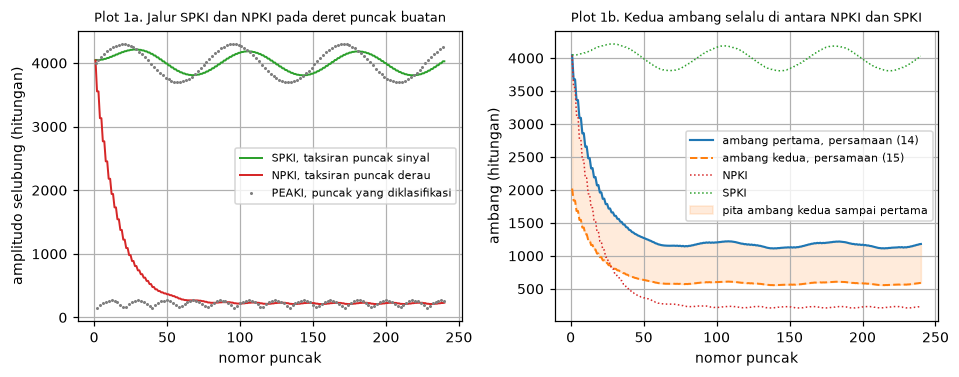

Plot 1 dicetak untuk 240 puncak buatan.
  nilai awal P3-1, maksimum 4 puncak pertama : 4049
  jumlah puncak diklasifikasi sinyal     : 119
  jumlah puncak diklasifikasi derau      : 121
  SPKI akhir                             : 4028
  NPKI akhir                             : 232
  ambang pertama akhir                   : 1181.000000
  ambang kedua akhir                     : 590.500000
  rasio ambang kedua terhadap pertama    : 0.500000


In [5]:
# Tujuan: memplot jalur SPKI dan NPKI beserta kedua ambang pada deret puncak buatan.
# Cell ini menampilkan Plot 1 dengan dua panel dan mencetak jumlah puncak sinyal, jumlah puncak derau,
# letak kedua ambang akhir, dan rasio ambang kedua terhadap ambang pertama.

rng_plot1 = np.random.default_rng(17)
deret_plot1 = []
for i in range(120):
    deret_plot1.append(int(4000 + 300 * np.sin(i / 6.0)))
    deret_plot1.append(int(150 + 120 * abs(np.sin(i / 3.0))))
deret_plot1 = np.array(deret_plot1, dtype=np.int64)
N_AWAL_PLOT1 = 4     # deret ini dua puncak per detik, jadi dua detik pertama adalah empat puncak
awal_plot1, _ = nilai_awal_taksiran(deret_plot1, N_AWAL_PLOT1)
df_plot1 = jalankan_ambang(deret_plot1, mode="floor", n_awal=N_AWAL_PLOT1)
n_sinyal = int((df_plot1["jenis"] == "sinyal").sum())
n_derau = int((df_plot1["jenis"] == "derau").sum())
t2_ratio = float((df_plot1["THRESHOLD_I2"] / df_plot1["THRESHOLD_I1"]).iloc[-1])

fig1, axs1 = plt.subplots(1, 2, figsize=(8.8, 3.5))
axs1[0].plot(df_plot1["n"], df_plot1["SPKI"], "C2-", lw=1.3, label="SPKI, taksiran puncak sinyal")
axs1[0].plot(df_plot1["n"], df_plot1["NPKI"], "C3-", lw=1.3, label="NPKI, taksiran puncak derau")
axs1[0].plot(df_plot1["n"], df_plot1["PEAKI"], "C7.", ms=2.0, label="PEAKI, puncak yang diklasifikasi")
axs1[0].set_title("Plot 1a. Jalur SPKI dan NPKI pada deret puncak buatan", fontsize=8.5)
axs1[0].set_xlabel("nomor puncak")
axs1[0].set_ylabel("amplitudo selubung (hitungan)")
axs1[0].legend(loc="center right", fontsize=7.5)
axs1[1].plot(df_plot1["n"], df_plot1["THRESHOLD_I1"], "C0-", lw=1.4, label="ambang pertama, persamaan (14)")
axs1[1].plot(df_plot1["n"], df_plot1["THRESHOLD_I2"], "C1--", lw=1.3, label="ambang kedua, persamaan (15)")
axs1[1].plot(df_plot1["n"], df_plot1["NPKI"], "C3:", lw=1.0, label="NPKI")
axs1[1].plot(df_plot1["n"], df_plot1["SPKI"], "C2:", lw=1.0, label="SPKI")
axs1[1].fill_between(df_plot1["n"], df_plot1["THRESHOLD_I2"], df_plot1["THRESHOLD_I1"],
                     color="C1", alpha=0.15, label="pita ambang kedua sampai pertama")
axs1[1].set_title("Plot 1b. Kedua ambang selalu di antara NPKI dan SPKI", fontsize=8.5)
axs1[1].set_xlabel("nomor puncak")
axs1[1].set_ylabel("ambang (hitungan)")
axs1[1].legend(loc="center right", fontsize=7.5)
fig1.tight_layout()
plt.show()

print("Plot 1 dicetak untuk", df_plot1["n"].iloc[-1], "puncak buatan.")
print("  nilai awal P3-1, maksimum", N_AWAL_PLOT1, "puncak pertama :", awal_plot1)
print("  jumlah puncak diklasifikasi sinyal     :", n_sinyal)
print("  jumlah puncak diklasifikasi derau      :", n_derau)
print("  SPKI akhir                             :", int(df_plot1["SPKI"].iloc[-1]))
print("  NPKI akhir                             :", int(df_plot1["NPKI"].iloc[-1]))
print("  ambang pertama akhir                   : %.6f" % float(df_plot1["THRESHOLD_I1"].iloc[-1]))
print("  ambang kedua akhir                     : %.6f" % float(df_plot1["THRESHOLD_I2"].iloc[-1]))
print("  rasio ambang kedua terhadap pertama    : %.6f" % t2_ratio)

assert abs(t2_ratio - RASIO_AMBANG2) < 1e-12, "ambang kedua harus tepat separuh ambang pertama"
HASIL["rasio ambang kedua terukur"] = float(t2_ratio)
HASIL["puncak buatan diklasifikasi sinyal"] = n_sinyal
HASIL["puncak buatan diklasifikasi derau"] = n_derau


## 7. Tabel hitung tangan jejak ambang

Deret puncak buatan di bawah berisi empat belas puncak yang bergantian sinyal dan derau. Seluruhnya
bilangan bulat, dan deret ini mewakili satu puncak per detik, sehingga dua detik pertama adalah dua
puncak pertama dan taksirannya mulai dari maksimum kedua puncak itu sesuai keputusan P3-1. Baris
pertama, yang nilainya sama dengan maksimum itu, karena itu belum melewati ambang dan tergolong
derau. Kolomnya satu kolom per suku, sesuai bentuk dua suku persamaan (12) dan (13):

$$ SPKI_{\text{baru}} = 0{,}125 \, PEAKI + 0{,}875 \, SPKI_{\text{lama}} $$

Perhatikan bahwa setiap baris mengisi hanya satu dari dua kolom suku, karena satu puncak hanya
memutakhirkan salah satu variabel. Kolom yang tidak terisi diberi tanda kosong, dan itulah bukti
tabel bahwa klasifikasi mendahului pembaruan.


In [6]:
# Tujuan: menghitung jejak ambang dengan tangan untuk deret puncak buatan empat belas puncak.
# Cell ini mencetak tabel dengan satu kolom per suku, tabel padanan aritmetika geser, dan membaca
# satu baris secara rinci.

deret_tangan = np.array([4000, 120, 3200, 160, 4800, 200, 2400, 240, 4000, 280, 3600, 320, 4400, 360],
                        dtype=np.int64)
N_AWAL_TANGAN = 2    # deret ini satu puncak per detik, jadi dua detik pertama adalah dua puncak
awal_tangan, _ = nilai_awal_taksiran(deret_tangan, N_AWAL_TANGAN)
spki_t, npki_t = awal_tangan, awal_tangan
spki_p_t, npki_p_t = float(awal_tangan), float(awal_tangan)
t1_t = float(awal_tangan)
baris_tangan = []
for n, p in enumerate(deret_tangan, start=1):
    p = int(p)
    jenis = "sinyal" if p > t1_t else "derau"
    suku_puncak = BOBOT_NORMAL * p
    if jenis == "sinyal":
        suku_lama = (1.0 - BOBOT_NORMAL) * spki_p_t
        spki_p_t = suku_puncak + suku_lama
        spki_t = update_bulat(spki_t, p, "floor")
        baris_tangan.append({"n": n, "PEAKI": p, "jenis": jenis,
                             "0,125 PEAKI": round(suku_puncak, 6),
                             "0,875 SPKI lama": round(suku_lama, 6), "0,875 NPKI lama": "",
                             "SPKI baru": round(spki_p_t, 6), "NPKI baru": round(npki_p_t, 6)})
    else:
        suku_lama = (1.0 - BOBOT_NORMAL) * npki_p_t
        npki_p_t = suku_puncak + suku_lama
        npki_t = update_bulat(npki_t, p, "floor")
        baris_tangan.append({"n": n, "PEAKI": p, "jenis": jenis,
                             "0,125 PEAKI": round(suku_puncak, 6),
                             "0,875 SPKI lama": "", "0,875 NPKI lama": round(suku_lama, 6),
                             "SPKI baru": round(spki_p_t, 6), "NPKI baru": round(npki_p_t, 6)})
    t1_t = npki_p_t + BOBOT_SELISIH * (spki_p_t - npki_p_t)
    baris_tangan[-1]["THRESHOLD_I1"] = round(t1_t, 6)
    baris_tangan[-1]["THRESHOLD_I2"] = round(RASIO_AMBANG2 * t1_t, 6)
df_tangan = pd.DataFrame(baris_tangan)
print("tabel hitung tangan, satu kolom per suku, taksiran mulai dari maksimum dua puncak pertama:",
      awal_tangan)
print(df_tangan.to_string(index=False))
print()
df_tangan_bulat = jalankan_ambang(deret_tangan, mode="floor", n_awal=N_AWAL_TANGAN)
print("padanan aritmetika geser pada deret yang sama, SPKI bulat lawan SPKI pecahan:")
print(df_tangan_bulat[["n", "PEAKI", "jenis", "SPKI", "NPKI", "SPKI pecahan", "NPKI pecahan"]]
      .round(4).to_string(index=False))
print()
baris_baca = 5
print("baris n =", baris_baca, "dibaca begini: PEAKI =", int(deret_tangan[baris_baca - 1]),
      "berjenis", df_tangan.loc[baris_baca - 1, "jenis"])
print("  suku puncak  0,125 kali PEAKI          :", df_tangan.loc[baris_baca - 1, "0,125 PEAKI"])
print("  suku lama    0,875 kali nilai sebelumnya:",
      df_tangan.loc[baris_baca - 1, "0,875 SPKI lama"]
      if df_tangan.loc[baris_baca - 1, "0,875 SPKI lama"] != ""
      else df_tangan.loc[baris_baca - 1, "0,875 NPKI lama"])
print("  jumlah kedua suku                      :", df_tangan.loc[baris_baca - 1, "SPKI baru"])
print("  ambang pertama sesudah baris ini       :", df_tangan.loc[baris_baca - 1, "THRESHOLD_I1"])
print("  ambang kedua sesudah baris ini         :", df_tangan.loc[baris_baca - 1, "THRESHOLD_I2"])
print()
print("jumlah baris tabel                     :", df_tangan.shape[0])
print("jumlah baris bertanda kosong pada kolom 0,875 SPKI:", int((df_tangan["0,875 SPKI lama"] == "").sum()))
print("jumlah baris bertanda kosong pada kolom 0,875 NPKI:", int((df_tangan["0,875 NPKI lama"] == "").sum()))

assert df_tangan.shape[0] == 14, "tabel hitung tangan harus memuat empat belas puncak"
assert int((df_tangan["0,875 SPKI lama"] == "").sum()) == int((df_tangan["jenis"] == "derau").sum())
assert int((df_tangan["0,875 NPKI lama"] == "").sum()) == int((df_tangan["jenis"] == "sinyal").sum())
kt = df_tangan.iloc[4]
jumlah_uji = kt["0,125 PEAKI"] + kt["0,875 SPKI lama"]
print("pemeriksaan baris 5 dengan toleransi 1e-9 :", bool(abs(jumlah_uji - kt["SPKI baru"]) < 1e-9))
assert abs(jumlah_uji - kt["SPKI baru"]) < 1e-9, "jumlah kedua suku harus sama dengan nilai barunya"
HASIL["baris tabel hitung tangan"] = int(df_tangan.shape[0])
HASIL["SPKI akhir tabel hitung tangan"] = float(df_tangan["SPKI baru"].iloc[-1])
HASIL["NPKI akhir tabel hitung tangan"] = float(df_tangan["NPKI baru"].iloc[-1])
print("lolos: tabel hitung tangan lengkap, setiap baris hanya mengisi satu kolom suku")


tabel hitung tangan, satu kolom per suku, taksiran mulai dari maksimum dua puncak pertama: 4000
 n  PEAKI  jenis  0,125 PEAKI 0,875 SPKI lama 0,875 NPKI lama   SPKI baru   NPKI baru  THRESHOLD_I1  THRESHOLD_I2
 1   4000  derau        500.0                          3500.0 4000.000000 4000.000000   4000.000000   2000.000000
 2    120  derau         15.0                          3500.0 4000.000000 3515.000000   3636.250000   1818.125000
 3   3200  derau        400.0                        3075.625 4000.000000 3475.625000   3606.718750   1803.359375
 4    160  derau         20.0                     3041.171875 4000.000000 3061.171875   3295.878906   1647.939453
 5   4800 sinyal        600.0          3500.0                 4100.000000 3061.171875   3320.878906   1660.439453
 6    200  derau         25.0                     2678.525391 4100.000000 2703.525391   3052.644043   1526.322021
 7   2400  derau        300.0                     2365.584717 4100.000000 2665.584717   3024.188538   1512

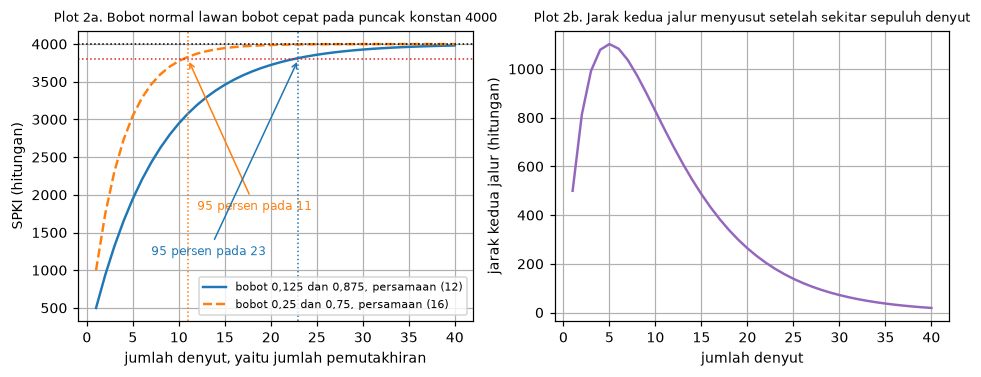

Plot 2 dicetak untuk 40 denyut pada puncak konstan 4000 .
  bobot normal, menyentuh 95 persen pada : 23 denyut
  bobot cepat , menyentuh 95 persen pada : 11 denyut
  percepatan                             : 2.0909 kali
  nilai pada denyut ke-5, normal         : 1948.3643
  nilai pada denyut ke-5, cepat          : 3050.7812
  jarak kedua jalur pada denyut ke-5     : 1102.4170
  jarak kedua jalur pada denyut ke-10    : 827.0482
  jarak kedua jalur pada denyut ke-20    : 264.1502
  jarak terbesar kedua jalur             : 1102.4170


In [7]:
# Tujuan: membandingkan bobot normal persamaan (12) dengan bobot cepat persamaan (16) pada deret yang sama.
# Cell ini menampilkan Plot 2 dengan dua panel dan mencetak jumlah denyut sampai 95 persen, nilai akhir,
# dan jarak nilai pada beberapa denyut untuk kedua bobot.

PUNCAK_PANEL = 4000
PANJANG_PANEL = 40
j_normal = jejak_pecahan(PUNCAK_PANEL, BOBOT_NORMAL, PANJANG_PANEL)
j_cepat = jejak_pecahan(PUNCAK_PANEL, BOBOT_LEWAT_AMBANG2, PANJANG_PANEL)
n95n = jumlah_sampai(j_normal, 0.95 * PUNCAK_PANEL)
n95c = jumlah_sampai(j_cepat, 0.95 * PUNCAK_PANEL)
jarak = np.abs(j_cepat - j_normal)

fig2, axs2 = plt.subplots(1, 2, figsize=(8.8, 3.5))
axs2[0].plot(np.arange(1, PANJANG_PANEL + 1), j_normal, "C0-", lw=1.6,
             label="bobot 0,125 dan 0,875, persamaan (12)")
axs2[0].plot(np.arange(1, PANJANG_PANEL + 1), j_cepat, "C1--", lw=1.6,
             label="bobot 0,25 dan 0,75, persamaan (16)")
axs2[0].axhline(PUNCAK_PANEL, color="k", ls=":", lw=1.0)
axs2[0].axhline(0.95 * PUNCAK_PANEL, color="C3", ls=":", lw=1.0)
axs2[0].axvline(n95n, color="C0", ls=":", lw=1.0)
axs2[0].axvline(n95c, color="C1", ls=":", lw=1.0)
axs2[0].annotate("95 persen pada %d" % n95c, xy=(n95c, 0.95 * PUNCAK_PANEL), xytext=(n95c + 1.0, 0.45 * PUNCAK_PANEL),
                 color="C1", fontsize=8, arrowprops=dict(arrowstyle="->", color="C1"))
axs2[0].annotate("95 persen pada %d" % n95n, xy=(n95n, 0.95 * PUNCAK_PANEL), xytext=(n95n - 16.0, 0.30 * PUNCAK_PANEL),
                 color="C0", fontsize=8, arrowprops=dict(arrowstyle="->", color="C0"))
axs2[0].set_title("Plot 2a. Bobot normal lawan bobot cepat pada puncak konstan %d" % PUNCAK_PANEL, fontsize=8.5)
axs2[0].set_xlabel("jumlah denyut, yaitu jumlah pemutakhiran")
axs2[0].set_ylabel("SPKI (hitungan)")
axs2[0].legend(loc="lower right", fontsize=7.5)
axs2[1].plot(np.arange(1, PANJANG_PANEL + 1), jarak, "C4-", lw=1.6)
axs2[1].set_title("Plot 2b. Jarak kedua jalur menyusut setelah sekitar sepuluh denyut", fontsize=8.5)
axs2[1].set_xlabel("jumlah denyut")
axs2[1].set_ylabel("jarak kedua jalur (hitungan)")
fig2.tight_layout()
plt.show()

print("Plot 2 dicetak untuk", PANJANG_PANEL, "denyut pada puncak konstan", PUNCAK_PANEL, ".")
print("  bobot normal, menyentuh 95 persen pada :", n95n, "denyut")
print("  bobot cepat , menyentuh 95 persen pada :", n95c, "denyut")
print("  percepatan                             : %.4f kali" % (n95n / n95c))
print("  nilai pada denyut ke-5, normal         : %.4f" % j_normal[4])
print("  nilai pada denyut ke-5, cepat          : %.4f" % j_cepat[4])
print("  jarak kedua jalur pada denyut ke-5     : %.4f" % jarak[4])
print("  jarak kedua jalur pada denyut ke-10    : %.4f" % jarak[9])
print("  jarak kedua jalur pada denyut ke-20    : %.4f" % jarak[19])
print("  jarak terbesar kedua jalur             : %.4f" % jarak.max())

assert n95c < n95n, "bobot cepat harus menyentuh 95 persen lebih awal"
assert jarak.max() > 0.0, "kedua jalur harus berbeda"
HASIL["jarak terbesar bobot normal lawan cepat"] = float(jarak.max())


## 8. Risiko pemotongan separuh ambang pada irama tidak teratur

Persamaan (22) dan (23) memotong separuh ambang pertama kedua domain bila irama dinilai tidak
teratur. Bentuk keduanya adalah pembaruan di tempat:

$$ THRESHOLD_{I1} \leftarrow 0{,}5 \, THRESHOLD_{I1}, \qquad THRESHOLD_{F1} \leftarrow 0{,}5 \, THRESHOLD_{F1} $$

Motifnya benar, yaitu menaikkan kepekaan supaya denyut tidak terlewat. Namun konsekuensinya harus
dihitung, karena ambang kedua mengikuti ambang pertama sebagai separuhnya, sehingga memotong ambang
pertama separuh berarti memotong ambang kedua menjadi seperempat nilai asalnya:

$$ THRESHOLD_{I2} = 0{,}5 \, THRESHOLD_{I1} \quad \longrightarrow \quad THRESHOLD_{I2} = 0{,}5 \left( 0{,}5 \, THRESHOLD_{I1} \right) = 0{,}25 \, THRESHOLD_{I1} $$

Pada irama fibrilasi atrium, kondisi tidak teratur berjalan hampir sepanjang rekaman, sehingga
pemotongan itu nyaris selalu aktif. Sel berikut mengukur harganya pada dua tingkat: deret puncak
teratur buatan, dan rekaman nyata AFDB `04015`.


In [8]:
# Tujuan: mengukur akibat pemotongan separuh ambang persamaan (22) dan (23) pada deret puncak teratur buatan.
# Cell ini mencetak jumlah puncak derau yang lolos ambang kedua dengan dan tanpa pemotongan separuh,
# jumlah puncak derau yang lolos ambang pertama, dan letak ambang minimumnya.

def deret_teratur(n_denyut=60, amplitudo_qrs=4000, rerata_derau=150.0, seed=5):
    """Deret puncak teratur: satu puncak QRS tiap 250 sampel dan dua puncak derau di antaranya."""
    panjang = n_denyut * int(FS_BOARD)
    v = np.zeros(panjang, dtype=np.int64)
    rng_t = np.random.default_rng(seed)
    amp_derau = rng_t.exponential(rerata_derau, size=n_denyut * 2)
    for b in range(n_denyut):
        v[b * int(FS_BOARD) + 50] = int(amplitudo_qrs)
    for j in range(n_denyut * 2):
        pos = j * 125 + 120
        if pos < panjang:
            v[pos] = int(amp_derau[j])
    return v


def ukur_lolos_ambang(v, potong_separuh):
    """Hitung puncak yang lolos ambang kedua dan ambang pertama sepanjang deret."""
    puncak = deteksi_puncak(v)
    awal_v, _ = nilai_awal_taksiran(v)
    spki, npki = float(awal_v), float(awal_v)
    t1 = npki + BOBOT_SELISIH * (spki - npki)
    t2 = RASIO_AMBANG2 * t1
    lolos1, lolos2, t1min, t2min = 0, 0, None, None
    for p in puncak:
        nilai = float(v[p])
        if nilai > t1:
            lolos1 += 1
            spki = BOBOT_NORMAL * nilai + (1.0 - BOBOT_NORMAL) * spki
        else:
            npki = BOBOT_NORMAL * nilai + (1.0 - BOBOT_NORMAL) * npki
        if t2 < nilai <= t1:
            lolos2 += 1
        t1 = npki + BOBOT_SELISIH * (spki - npki)
        if potong_separuh:
            t1 = 0.5 * t1
        t2 = RASIO_AMBANG2 * t1
        t1min = t1 if t1min is None else min(t1min, t1)
        t2min = t2 if t2min is None else min(t2min, t2)
    return {"puncak": len(puncak), "lolos1": lolos1, "lolos2": lolos2,
            "t1min": t1min, "t2min": t2min, "t1akhir": t1, "t2akhir": t2}


v_teratur = deret_teratur()
awal_teratur, _ = nilai_awal_taksiran(v_teratur)
tanpa = ukur_lolos_ambang(v_teratur, potong_separuh=False)
dengan = ukur_lolos_ambang(v_teratur, potong_separuh=True)
print("deret puncak teratur buatan, panjang", v_teratur.size, "sampel, 60 denyut pada", int(FS_BOARD), "Hz")
print("  nilai awal P3-1, maksimum", SAMPEL_INISIALISASI, "sampel pertama :", awal_teratur)
print("  jumlah puncak terdeteksi            :", tanpa["puncak"])
print("tanpa pemotongan separuh:")
print("  puncak lolos ambang pertama         :", tanpa["lolos1"])
print("  puncak derau lolos ambang kedua     :", tanpa["lolos2"])
print("  ambang pertama minimum              : %.6f" % tanpa["t1min"])
print("  ambang kedua minimum                : %.6f" % tanpa["t2min"])
print("dengan pemotongan separuh:")
print("  puncak lolos ambang pertama         :", dengan["lolos1"])
print("  puncak derau lolos ambang kedua     :", dengan["lolos2"])
print("  ambang pertama minimum              : %.6f" % dengan["t1min"])
print("  ambang kedua minimum                : %.6f" % dengan["t2min"])
print("perbandingan:")
print("  pertambahan puncak derau pada ambang kedua: %d menjadi %d, yaitu %.4f kali"
      % (tanpa["lolos2"], dengan["lolos2"], dengan["lolos2"] / max(tanpa["lolos2"], 1)))
print("  pertambahan puncak pada ambang pertama    : %d menjadi %d, yaitu %.4f kali"
      % (tanpa["lolos1"], dengan["lolos1"], dengan["lolos1"] / max(tanpa["lolos1"], 1)))
print("  ambang pertama minimum turun menjadi      : %.6f kali semula"
      % (dengan["t1min"] / tanpa["t1min"]))

assert dengan["lolos2"] > tanpa["lolos2"], "pemotongan separuh harus meloloskan lebih banyak puncak derau"
assert dengan["t1min"] < tanpa["t1min"], "ambang minimum harus turun karena pemotongan separuh"
HASIL["derau lolos ambang kedua tanpa potong"] = int(tanpa["lolos2"])
HASIL["derau lolos ambang kedua dengan potong"] = int(dengan["lolos2"])
HASIL["rasio derau lolos ambang kedua"] = float(dengan["lolos2"] / max(tanpa["lolos2"], 1))
HASIL["ambang pertama minimum tanpa potong"] = float(tanpa["t1min"])
HASIL["ambang pertama minimum dengan potong"] = float(dengan["t1min"])
print("lolos: pemotongan separuh meloloskan lebih banyak puncak derau dan menurunkan ambang minimum")


deret puncak teratur buatan, panjang 15000 sampel, 60 denyut pada 250 Hz
  nilai awal P3-1, maksimum 500 sampel pertama : 4000
  jumlah puncak terdeteksi            : 177
tanpa pemotongan separuh:
  puncak lolos ambang pertama         : 59
  puncak derau lolos ambang kedua     : 2
  ambang pertama minimum              : 1086.100643
  ambang kedua minimum                : 543.050322
dengan pemotongan separuh:
  puncak lolos ambang pertama         : 60
  puncak derau lolos ambang kedua     : 15
  ambang pertama minimum              : 496.501779
  ambang kedua minimum                : 248.250890
perbandingan:
  pertambahan puncak derau pada ambang kedua: 2 menjadi 15, yaitu 7.5000 kali
  pertambahan puncak pada ambang pertama    : 59 menjadi 60, yaitu 1.0169 kali
  ambang pertama minimum turun menjadi      : 0.457142 kali semula
lolos: pemotongan separuh meloloskan lebih banyak puncak derau dan menurunkan ambang minimum


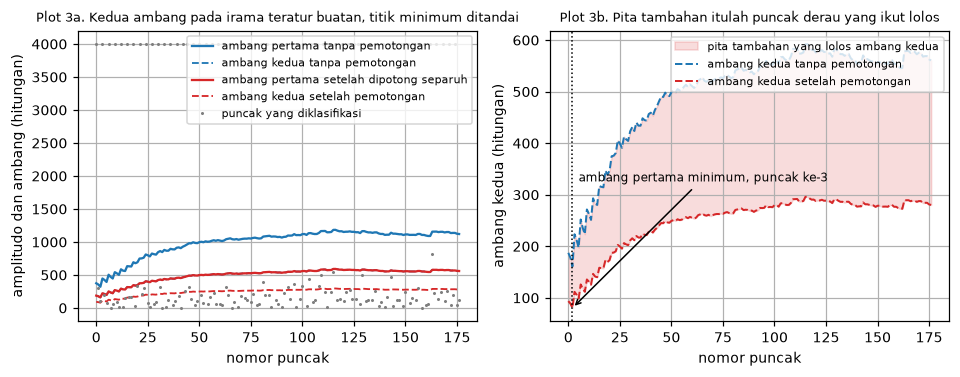

Plot 3 dicetak untuk 177 puncak pada irama teratur buatan.
  ambang pertama tanpa pemotongan, akhir : 1121.533918
  ambang pertama setelah pemotongan      : 560.766959
  ambang kedua tanpa pemotongan, akhir   : 560.766959
  ambang kedua setelah pemotongan        : 280.383479
  ambang pertama minimum ada di puncak ke: 3
  lebar pita tambahan, rata-rata         : 249.647566


In [9]:
# Tujuan: memplot akibat pemotongan separuh ambang pada irama teratur buatan.
# Cell ini menampilkan Plot 3 dengan dua panel dan mencetak letak kedua ambang pada tiap tahap,
# jumlah puncak derau yang lolos, dan titik ambang minimum.

puncak_teratur = deteksi_puncak(v_teratur)
spki_a, npki_a = float(awal_teratur), float(awal_teratur)
t1_a = npki_a + BOBOT_SELISIH * (spki_a - npki_a)
t2_a = RASIO_AMBANG2 * t1_a
jalur = {"t1_tanpa": [], "t2_tanpa": [], "t1_potong": [], "t2_potong": []}
sisa = {"spki": 0.0, "npki": 0.0}
for p in puncak_teratur:
    nilai = float(v_teratur[p])
    if nilai > t1_a:
        sisa["spki"] = BOBOT_NORMAL * nilai + (1.0 - BOBOT_NORMAL) * sisa["spki"]
    else:
        sisa["npki"] = BOBOT_NORMAL * nilai + (1.0 - BOBOT_NORMAL) * sisa["npki"]
    t1_a = sisa["npki"] + BOBOT_SELISIH * (sisa["spki"] - sisa["npki"])
    t2_a = RASIO_AMBANG2 * t1_a
    jalur["t1_tanpa"].append(t1_a)
    jalur["t2_tanpa"].append(t2_a)
    jalur["t1_potong"].append(0.5 * t1_a)
    jalur["t2_potong"].append(0.25 * t1_a)
for k in jalur:
    jalur[k] = np.array(jalur[k])
idx = np.arange(puncak_teratur.size)
i_min = int(np.argmin(jalur["t1_potong"]))

fig3, axs3 = plt.subplots(1, 2, figsize=(8.8, 3.5))
axs3[0].plot(idx, jalur["t1_tanpa"], "C0-", lw=1.5, label="ambang pertama tanpa pemotongan")
axs3[0].plot(idx, jalur["t2_tanpa"], "C0--", lw=1.2, label="ambang kedua tanpa pemotongan")
axs3[0].plot(idx, jalur["t1_potong"], "C3-", lw=1.5, label="ambang pertama setelah dipotong separuh")
axs3[0].plot(idx, jalur["t2_potong"], "C3--", lw=1.2, label="ambang kedua setelah pemotongan")
axs3[0].plot(idx, v_teratur[puncak_teratur], "C7.", ms=2.0, label="puncak yang diklasifikasi")
axs3[0].set_title("Plot 3a. Kedua ambang pada irama teratur buatan, titik minimum ditandai", fontsize=8.5)
axs3[0].set_xlabel("nomor puncak")
axs3[0].set_ylabel("amplitudo dan ambang (hitungan)")
axs3[0].legend(loc="upper right", fontsize=7.0)
axs3[1].fill_between(idx, jalur["t2_potong"], jalur["t2_tanpa"], color="C3", alpha=0.16,
                     label="pita tambahan yang lolos ambang kedua")
axs3[1].plot(idx, jalur["t2_tanpa"], "C0--", lw=1.3, label="ambang kedua tanpa pemotongan")
axs3[1].plot(idx, jalur["t2_potong"], "C3--", lw=1.3, label="ambang kedua setelah pemotongan")
axs3[1].axvline(i_min, color="k", ls=":", lw=1.0)
axs3[1].annotate("ambang pertama minimum, puncak ke-%d" % (i_min + 1),
                 xy=(i_min, jalur["t2_potong"][i_min]), xytext=(i_min + 3.0, jalur["t2_tanpa"].max() * 0.55),
                 fontsize=8, arrowprops=dict(arrowstyle="->", color="k"))
axs3[1].set_title("Plot 3b. Pita tambahan itulah puncak derau yang ikut lolos", fontsize=8.5)
axs3[1].set_xlabel("nomor puncak")
axs3[1].set_ylabel("ambang kedua (hitungan)")
axs3[1].legend(loc="upper right", fontsize=7.5)
fig3.tight_layout()
plt.show()

print("Plot 3 dicetak untuk", puncak_teratur.size, "puncak pada irama teratur buatan.")
print("  ambang pertama tanpa pemotongan, akhir : %.6f" % jalur["t1_tanpa"][-1])
print("  ambang pertama setelah pemotongan      : %.6f" % jalur["t1_potong"][-1])
print("  ambang kedua tanpa pemotongan, akhir   : %.6f" % jalur["t2_tanpa"][-1])
print("  ambang kedua setelah pemotongan        : %.6f" % jalur["t2_potong"][-1])
print("  ambang pertama minimum ada di puncak ke:", i_min + 1)
print("  lebar pita tambahan, rata-rata         : %.6f"
      % float((jalur["t2_tanpa"] - jalur["t2_potong"]).mean()))

assert jalur["t2_potong"][-1] < jalur["t2_tanpa"][-1], "ambang kedua setelah pemotongan harus lebih rendah"
HASIL["lebar pita tambahan rata-rata"] = float((jalur["t2_tanpa"] - jalur["t2_potong"]).mean())


## 9. Catatan fixed-point memakai konvensi terkunci

Konvensi di bawah ini dikunci tim dan dipakai seluruh fase. Ambang adaptif berada di ujung rantai,
sesudah turunan, sehingga seluruh skalanya ditentukan oleh dua keputusan sebelumnya.

1. Masukan rentangnya plus minus 5 mV dengan 12 bit signifikan, dijepit pada plus minus 2047
   hitungan, lalu diletakkan di depan kata 16 bit dengan nilai digeser ke kiri 4 bit.
2. Sesudah turunan lima titik, hasilnya digeser kanan 8 bit, sehingga faktor skala ambangnya 256.
3. Sesudah geser 8 itu, pengkuadratan muat di 32 bit dan jendela 38 sampel muat tepat di 32 bit.
4. Pembagian dengan 38 tidak dilakukan di RTL, sehingga ambangnya dikalikan 38.
5. Ambang apa pun yang ditulis dalam satuan milivolt dikalikan 256 lebih dulu, sesuai butir 2.
6. Konvensi gabungan kedua butir itu adalah faktor 9728 hitungan per milivolt pada ambang.

| Tahap | Nilai maksimum terukur | Lebar minimum | Catatan |
|---|---|---|---|
| Masukan | 32.752 hitungan | 16 bit | jepit 2047, geser kiri 4 bit |
| Turunan sesudah geser kanan 8 | 15.236 hitungan | 15 bit | faktor skala ambang 256 |
| Kuadrat sesudah geser 8 | 232.135.696 hitungan | 29 bit | masukan tahap ambang, muat 32 bit |
| Jendela 38 sesudah geser 8 | 2.053.318.817 hitungan | 32 bit | selubung energi, muat tepat 32 bit |

Untuk ambang adaptif sendiri, lebar kata yang dibutuhkan tidak ditentukan selubungnya, melainkan
taksirannya. Karena $SPKI$ dan $NPKI$ selalu di bawah atau sama dengan puncak tertinggi, dan karena
ambang pertama adalah rata-rata berbobot keduanya, seluruh bilangan di tahap ini muat di lebar kata
selubungnya. Yang perlu dijaga hanyalah bahwa akumulator tetap bilangan bulat dan bahwa pembagian
delapan adalah geser kanan, bukan pembagian titik apung.

Ada satu catatan penting tentang faktor 9728. Angka itu bukan skala fisis, melainkan skala
perbandingan. Yang dibandingkan di tahap ini adalah ambang dan selubung pada domain yang sama, jadi
yang harus konsisten hanyalah pangkat dua penggeseran dan pengali lebar jendela. Bila tim menulis
ambang dalam milivolt, urutannya adalah kalikan 256 lalu kalikan 38, dan tidak ada urutan lain yang
memberi hasil sama pada aritmetika bilangan bulat.


In [10]:
# Tujuan: memeriksa konsistensi aritmetika ambang pada konvensi terkunci dan menghitung skala ambang.
# Cell ini mencetak tabel faktor skala, lebar kata yang dibutuhkan taksiran, dan uji bahwa pembaruan
# bulat tidak pernah meluap melewati puncak tertinggi.

puncak_tertinggi = 2053318817            # selubung jendela 38 pada rekaman nyata, geser 8
spki_max, npki_max = puncak_tertinggi, puncak_tertinggi // 4
t1_max = npki_max + BOBOT_SELISIH * (spki_max - npki_max)


def lebar_bit(peak):
    n = int(abs(peak))
    return max(2, n.bit_length() + 1)


tabel_skala = pd.DataFrame([
    {"besaran": "faktor skala ambang, geser 8", "nilai": 2 ** 8},
    {"besaran": "pengali lebar jendela, pembagian tidak dilakukan", "nilai": LEBAR_JENDELA},
    {"besaran": "faktor gabungan ambang dalam mV", "nilai": (2 ** 8) * LEBAR_JENDELA},
    {"besaran": "rasio ambang kedua terhadap pertama", "nilai": RASIO_AMBANG2},
])
print("tabel faktor skala ambang pada konvensi terkunci:")
print(tabel_skala.to_string(index=False))
print()
print("lebar kata yang dibutuhkan taksiran pada selubung terlebar rekaman nyata:")
print("  puncak tertinggi selubung         :", puncak_tertinggi, "| lebar", lebar_bit(puncak_tertinggi), "bit")
print("  SPKI tertinggi yang mungkin       :", spki_max, "| lebar", lebar_bit(spki_max), "bit")
print("  NPKI tertinggi yang mungkin       :", npki_max, "| lebar", lebar_bit(npki_max), "bit")
print("  ambang pertama tertinggi mungkin  : %.6f | lebar %d bit" % (t1_max, lebar_bit(t1_max)))
print("  seluruhnya muat di kata 32 bit    :", bool(lebar_bit(t1_max) <= 32))
print()

# Uji meluap: pembaruan bulat pada deret puncak yang selalu di bawah puncak tertinggi.
rng_mu = np.random.default_rng(23)
deret_mu = rng_mu.integers(0, puncak_tertinggi, 4000).astype(np.int64)
spki_mu, npki_mu, t1_mu = 0, 0, 0.0
melewati = 0
for p in deret_mu:
    p = int(p)
    if p > t1_mu:
        spki_mu = update_bulat(spki_mu, p, "floor")
    else:
        npki_mu = update_bulat(npki_mu, p, "floor")
    t1_mu = npki_mu + BOBOT_SELISIH * (spki_mu - npki_mu)
    if spki_mu > puncak_tertinggi or npki_mu > puncak_tertinggi or t1_mu > puncak_tertinggi:
        melewati += 1
print("uji meluap pada", deret_mu.size, "puncak acak yang seluruhnya di bawah selubung tertinggi:")
print("  jumlah langkah yang melewati selubung tertinggi:", melewati)
print("  SPKI akhir                                     :", spki_mu)
print("  NPKI akhir                                     :", npki_mu)
print("  ambang pertama akhir                           : %.6f" % t1_mu)
print("  ambang tidak pernah melewati puncak tertinggi  :", bool(melewati == 0))

assert melewati == 0, "ambang tidak boleh melewati puncak tertinggi selubung"
assert lebar_bit(t1_max) <= 32, "ambang harus muat di kata 32 bit"
HASIL["faktor gabungan ambang (hitungan per mV)"] = (2 ** 8) * LEBAR_JENDELA
HASIL["lebar bit ambang maksimum"] = int(lebar_bit(t1_max))
print("lolos: ambang muat di kata 32 bit dan tidak pernah melewati puncak tertinggi selubung")


tabel faktor skala ambang pada konvensi terkunci:
                                         besaran  nilai
                    faktor skala ambang, geser 8  256.0
pengali lebar jendela, pembagian tidak dilakukan   38.0
                 faktor gabungan ambang dalam mV 9728.0
             rasio ambang kedua terhadap pertama    0.5

lebar kata yang dibutuhkan taksiran pada selubung terlebar rekaman nyata:
  puncak tertinggi selubung         : 2053318817 | lebar 32 bit
  SPKI tertinggi yang mungkin       : 2053318817 | lebar 32 bit
  NPKI tertinggi yang mungkin       : 513329704 | lebar 30 bit
  ambang pertama tertinggi mungkin  : 898326982.250000 | lebar 31 bit
  seluruhnya muat di kata 32 bit    : True

uji meluap pada 4000 puncak acak yang seluruhnya di bawah selubung tertinggi:
  jumlah langkah yang melewati selubung tertinggi: 0
  SPKI akhir                                     : 1556995291
  NPKI akhir                                     : 235820581
  ambang pertama akhir              

## 10. Tiga keputusan terkunci 19 Oktober 2026

Tiga keputusan tim untuk tahap ini dikunci pada 19 Oktober 2026, dan ketiganya diukur di bagian ini
pada rekaman uji terkunci AFDB `04015`. Rekaman itu dimuat satu kali di sel pertama bagian ini, lalu
dipakai kembali oleh bagian search back di bawahnya.

**P3-1. Inisialisasi SPKI dan NPKI dari maksimum dua detik pertama.** Halaman 233 dan 234 tidak
menetapkan nilai awal kedua taksiran itu. Nilai awal nol, yaitu cara yang berjalan tanpa keputusan
ini, membuat sekitar 23 denyut pertama terlalu sensitif, karena ambang pertama ikut mulai dari nol
sehingga kandidat paling awal selalu lolos sebagai puncak sinyal dan rata rata ambang selama
pemanasan jauh lebih rendah daripada maksimum dua detik pertama. Keputusan tim adalah kedua taksiran
mulai dari maksimum dua detik pertama sinyal, yaitu 500 sampel pertama pada 250 Hz. Aturan itu
berlaku sama pada kedua domain, pada selubung integrasi dan pada EKG terfilter.

**P3-3. Kriteria irama tidak teratur sebagai satu tetapan bernama.** Persamaan (22) dan (23) hanya
aktif bila irama dinilai tidak teratur. Batasnya diturunkan dari batas RR fase 4: selang RR di luar
0,92 sampai 1,16 kali rata-rata dianggap tidak teratur. Definisi itu ditulis satu kali sebagai satu
tetapan bernama, supaya model dan RTL memakai angka yang sama persis dan tidak ada angka yang sama
disebar di beberapa sel.

**P3-5. Satu puncak disebut QRS hanya bila lolos kedua domain.** Kalimat nomor 9 halaman 234
mensyaratkan pengenalan pada kedua gelombang. Karena itu puncak harus lolos ambang domain integrasi
dan ambang domain EKG terfilter, sedangkan prosedur search back hanya membuka ambang domain
integrasi, yaitu ambang kedua domain integrasi, dan tidak pernah membuka ambang domain EKG terfilter.

In [11]:
# Tujuan: memuat rekaman uji terkunci AFDB 04015 satu kali untuk seluruh bagian keputusan terkunci
# dan bagian search back, lalu mencetak header rekaman, statistik kedua domain, jumlah puncak
# kandidat, dan nilai awal P3-1.
# Cell ini mencetak nama rekaman, laju sampel, jumlah sampel, detik, kanal, resolusi, maksimum dan
# median selubung integrasi dan EKG terfilter, jumlah puncak kandidat, dan nilai awal kedua domain.

rekaman_ada = REKAMAN.with_suffix(".hea").exists() and (REKAMAN.parent / (REKAMAN.name + ".dat")).exists()
assert rekaman_ada, "rekaman AFDB 04015 harus tersedia di jalur terkunci"

import wfdb

rec = wfdb.rdrecord(str(REKAMAN), sampto=450000)
sinyal_nyata = rec.p_signal[:, 0].astype(float)
x_nyata = kuantisasi(sinyal_nyata)
_, y2_nyata, z3_nyata = rantai_tapis(x_nyata)
sq_nyata = (z3_nyata >> GESER_AMBANG) ** 2
selubung_nyata = jendela_jumlah(sq_nyata, LEBAR_JENDELA)
puncak_nyata = deteksi_puncak(selubung_nyata)
terfilter_nyata = np.abs(y2_nyata)          # amplitudo domain EKG terfilter, yaitu bandpass terkunci

AWAL_I = nilai_awal_taksiran(selubung_nyata)     # P3-1, dua detik pertama selubung integrasi
AWAL_F = nilai_awal_taksiran(terfilter_nyata)    # P3-1, dua detik pertama EKG terfilter

assert puncak_nyata.size > 1000, "rekaman harus menghasilkan ribuan puncak"
print("rekaman            :", rec.record_name, rec.fs, "Hz,", sinyal_nyata.size, "sampel,",
      int(sinyal_nyata.size / rec.fs), "detik, kanal", rec.sig_name[0], rec.adc_res[0], "bit")
print("selubung integrasi : puncak", int(selubung_nyata.max()), "| median",
      float(np.median(selubung_nyata)))
print("EKG terfilter      : puncak", int(terfilter_nyata.max()), "| median",
      float(np.median(terfilter_nyata)))
print("puncak kandidat    :", puncak_nyata.size)
print("nilai awal P3-1    :", SAMPEL_INISIALISASI, "sampel pertama, yaitu", DURASI_INISIALISASI,
      "detik pada", FS_BOARD, "Hz")
print("  SPKI0 = NPKI0    :", AWAL_I[0], "hitungan pada selubung integrasi,", AWAL_F[0],
      "hitungan pada EKG terfilter")
HASIL["AFDB puncak terdeteksi"] = int(puncak_nyata.size)
HASIL["AFDB nilai awal selubung (hitungan)"] = int(AWAL_I[0])
HASIL["AFDB nilai awal terfilter (hitungan)"] = int(AWAL_F[0])

rekaman            : 04015 250 Hz, 450000 sampel, 1800 detik, kanal ECG1 12 bit
selubung integrasi : puncak 2053318817 | median 4512293.5
EKG terfilter      : puncak 19286208 | median 1323632.0
puncak kandidat    : 4805
nilai awal P3-1    : 500 sampel pertama, yaitu 2.0 detik pada 250.0 Hz
  SPKI0 = NPKI0    : 134212679 hitungan pada selubung integrasi, 4783664 hitungan pada EKG terfilter


perilaku 23 kandidat pertama rekaman uji AFDB 04015, dua cara inisialisasi:
cara nol:
  SPKI0 = NPKI0                     : 0 hitungan
  ambang pertama awal               : 0.000000 hitungan
  ambang kedua awal                 : 0.000000 hitungan
  kandidat lolos ambang pertama     : 13 dari 23
  kandidat lolos ambang kedua       : 2
  rata rata ambang pertama 23 kandidat: 17641608.782570 hitungan
  rata rata itu terhadap nilai awal : 0.131445 kali
  kandidat pertama lolos ambang pertama: True
  lima kandidat pertama lolos       : 4 dari 5
  ambang pertama pada kandidat ke-23 : 28875135.151415 hitungan
cara maksimum dua detik:
  SPKI0 = NPKI0                     : 134212679 hitungan
  ambang pertama awal               : 134212679.000000 hitungan
  ambang kedua awal                 : 67106339.500000 hitungan
  kandidat lolos ambang pertama     : 11 dari 23
  kandidat lolos ambang kedua       : 1
  rata rata ambang pertama 23 kandidat: 90206051.946081 hitungan
  rata rata itu terhadap ni

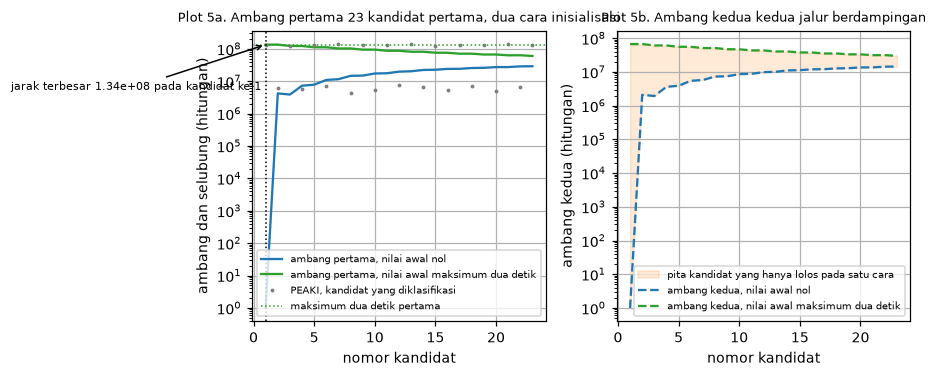

lolos: kedua cara inisialisasi diukur pada 23 kandidat pertama, dan kedua jalur ambangnya dicetak berdampingan


In [12]:
# Tujuan: membandingkan inisialisasi nol dengan inisialisasi maksimum dua detik pertama, yaitu
# keputusan P3-1, pada 23 kandidat pertama rekaman uji AFDB 04015, dan memplot kedua jalur ambang
# itu berdampingan.
# Cell ini mencetak nilai awal dan ambang awal kedua cara, jumlah kandidat yang lolos ambang
# pertama dan ambang kedua pada masing masing cara, jarak terbesar kedua jalur, dan selisih
# jumlah kandidat tiap ambang.

PANJANG_BANDING = 23
CARA_AWAL = (("nol", 0), ("maksimum dua detik", int(AWAL_I[0])))


def jalur_banding(nilai_awal, panjang=PANJANG_BANDING):
    """Persamaan (12) sampai (15) pada kandidat pertama rekaman, untuk satu pilihan nilai awal."""
    spki, npki = float(nilai_awal), float(nilai_awal)
    t1 = npki + BOBOT_SELISIH * (spki - npki)
    t2 = RASIO_AMBANG2 * t1
    baris = []
    for n, p in enumerate(puncak_nyata[:panjang], start=1):
        nilai = float(selubung_nyata[p])
        lolos1 = bool(nilai > t1)
        if lolos1:
            spki = BOBOT_NORMAL * nilai + (1.0 - BOBOT_NORMAL) * spki
        else:
            npki = BOBOT_NORMAL * nilai + (1.0 - BOBOT_NORMAL) * npki
        baris.append({"n": n, "PEAKI": nilai, "lolos ambang pertama": lolos1,
                      "lolos ambang kedua": bool(t2 < nilai <= t1),
                      "THRESHOLD_I1": t1, "THRESHOLD_I2": t2})
        t1 = npki + BOBOT_SELISIH * (spki - npki)
        t2 = RASIO_AMBANG2 * t1
    return pd.DataFrame(baris)


tabel_banding = {}
for nama, awal in CARA_AWAL:
    tabel_banding[nama] = jalur_banding(awal)

lolos1_nol = int(tabel_banding["nol"]["lolos ambang pertama"].sum())
lolos2_nol = int(tabel_banding["nol"]["lolos ambang kedua"].sum())
lolos1_maks = int(tabel_banding["maksimum dua detik"]["lolos ambang pertama"].sum())
lolos2_maks = int(tabel_banding["maksimum dua detik"]["lolos ambang kedua"].sum())
jalur_i1_nol = tabel_banding["nol"]["THRESHOLD_I1"].to_numpy()
jalur_i1_maks = tabel_banding["maksimum dua detik"]["THRESHOLD_I1"].to_numpy()
assert jalur_i1_nol.shape == jalur_i1_maks.shape, "kedua jalur pembanding harus sama panjang"
selisih_ambang = jalur_i1_nol - jalur_i1_maks
posisi_jarak = int(np.argmax(np.abs(selisih_ambang))) + 1
rata_t1_nol = float(tabel_banding["nol"]["THRESHOLD_I1"].mean())
rata_t1_maks = float(tabel_banding["maksimum dua detik"]["THRESHOLD_I1"].mean())
lolos_lima_nol = int(tabel_banding["nol"]["lolos ambang pertama"].iloc[:5].sum())
lolos_lima_maks = int(tabel_banding["maksimum dua detik"]["lolos ambang pertama"].iloc[:5].sum())

print("perilaku", PANJANG_BANDING, "kandidat pertama rekaman uji AFDB 04015, dua cara inisialisasi:")
for nama, awal in CARA_AWAL:
    df = tabel_banding[nama]
    print("cara %s:" % nama)
    print("  SPKI0 = NPKI0                     :", awal, "hitungan")
    print("  ambang pertama awal               : %.6f hitungan" % float(df["THRESHOLD_I1"].iloc[0]))
    print("  ambang kedua awal                 : %.6f hitungan" % float(df["THRESHOLD_I2"].iloc[0]))
    print("  kandidat lolos ambang pertama     :", int(df["lolos ambang pertama"].sum()), "dari", len(df))
    print("  kandidat lolos ambang kedua       :", int(df["lolos ambang kedua"].sum()))
    print("  rata rata ambang pertama 23 kandidat: %.6f hitungan" % float(df["THRESHOLD_I1"].mean()))
    print("  rata rata itu terhadap nilai awal : %.6f kali"
          % (float(df["THRESHOLD_I1"].mean()) / AWAL_I[0]))
    print("  kandidat pertama lolos ambang pertama:", bool(df["lolos ambang pertama"].iloc[0]))
    print("  lima kandidat pertama lolos       :", int(df["lolos ambang pertama"].iloc[:5].sum()), "dari 5")
    print("  ambang pertama pada kandidat ke-%d : %.6f hitungan"
          % (PANJANG_BANDING, float(df["THRESHOLD_I1"].iloc[-1])))
print()
print("jarak kedua jalur ambang pertama pada jendela pembanding:")
print("  jarak terbesar                    : %.6f hitungan" % float(np.abs(selisih_ambang).max()))
print("  jarak itu ada pada kandidat ke    :", posisi_jarak)
print("  jarak rata rata                   : %.6f hitungan" % float(np.abs(selisih_ambang).mean()))
print("perbandingan kepekaan kedua cara pada jendela pembanding:")
print("  rata rata ambang pertama, nol lawan maksimum: %.6f lawan %.6f hitungan"
      % (rata_t1_nol, rata_t1_maks))
print("  rata rata ambang nol hanya %.6f kali rata rata ambang maksimum"
      % (rata_t1_nol / rata_t1_maks))
print("  lima kandidat pertama yang lolos, nol lawan maksimum: %d lawan %d dari 5"
      % (lolos_lima_nol, lolos_lima_maks))
print("selisih jumlah kandidat, maksimum dua detik dikurangi nol:")
print("  ambang pertama                    :", lolos1_maks - lolos1_nol, "kandidat, yaitu %d menjadi %d"
      % (lolos1_nol, lolos1_maks))
print("  ambang kedua                      :", lolos2_maks - lolos2_nol, "kandidat, yaitu %d menjadi %d"
      % (lolos2_nol, lolos2_maks))

fig5, axs5 = plt.subplots(1, 2, figsize=(8.8, 3.5))
axs5[0].semilogy(tabel_banding["nol"]["n"], np.maximum(jalur_i1_nol, 1.0), "C0-", lw=1.5,
                 label="ambang pertama, nilai awal nol")
axs5[0].semilogy(tabel_banding["maksimum dua detik"]["n"], np.maximum(jalur_i1_maks, 1.0), "C2-", lw=1.5,
                 label="ambang pertama, nilai awal maksimum dua detik")
axs5[0].semilogy(tabel_banding["nol"]["n"], np.maximum(tabel_banding["nol"]["PEAKI"], 1.0), "C7.", ms=3.0,
                 label="PEAKI, kandidat yang diklasifikasi")
axs5[0].axhline(AWAL_I[0], color="C2", ls=":", lw=1.0, label="maksimum dua detik pertama")
axs5[0].axvline(posisi_jarak, color="k", ls=":", lw=1.0)
axs5[0].annotate("jarak terbesar %.3g pada kandidat ke-%d" % (float(np.abs(selisih_ambang).max()), posisi_jarak),
                 xy=(posisi_jarak, max(float(jalur_i1_maks[posisi_jarak - 1]), 1.0)),
                 xytext=(posisi_jarak - 21.0, 0.04 * AWAL_I[0]), fontsize=7.5,
                 arrowprops=dict(arrowstyle="->", color="k"))
axs5[0].set_title("Plot 5a. Ambang pertama 23 kandidat pertama, dua cara inisialisasi", fontsize=8.5)
axs5[0].set_xlabel("nomor kandidat")
axs5[0].set_ylabel("ambang dan selubung (hitungan)")
axs5[0].legend(loc="lower right", fontsize=6.8)
jalur_i2_nol = tabel_banding["nol"]["THRESHOLD_I2"].to_numpy()
jalur_i2_maks = tabel_banding["maksimum dua detik"]["THRESHOLD_I2"].to_numpy()
axs5[1].fill_between(tabel_banding["nol"]["n"], np.maximum(jalur_i2_maks, 1.0), np.maximum(jalur_i2_nol, 1.0),
                     color="C1", alpha=0.16, label="pita kandidat yang hanya lolos pada satu cara")
axs5[1].semilogy(tabel_banding["nol"]["n"], np.maximum(jalur_i2_nol, 1.0), "C0--", lw=1.5,
                 label="ambang kedua, nilai awal nol")
axs5[1].semilogy(tabel_banding["maksimum dua detik"]["n"], np.maximum(jalur_i2_maks, 1.0), "C2--", lw=1.5,
                 label="ambang kedua, nilai awal maksimum dua detik")
axs5[1].set_title("Plot 5b. Ambang kedua kedua jalur berdampingan", fontsize=8.5)
axs5[1].set_xlabel("nomor kandidat")
axs5[1].set_ylabel("ambang kedua (hitungan)")
axs5[1].legend(loc="lower right", fontsize=6.8)
fig5.tight_layout()
plt.show()

assert lolos1_nol > lolos1_maks, "inisialisasi nol harus meloloskan lebih banyak kandidat"
assert rata_t1_nol < rata_t1_maks, "inisialisasi nol harus memberi ambang rata rata lebih rendah"
assert lolos_lima_nol >= lolos_lima_maks, "inisialisasi nol tidak boleh kalah peka pada lima kandidat pertama"
assert posisi_jarak >= 1, "letak jarak terbesar harus sah"
HASIL["P3-1 kandidat lolos ambang pertama, awal nol"] = lolos1_nol
HASIL["P3-1 kandidat lolos ambang pertama, awal maksimum"] = lolos1_maks
HASIL["P3-1 kandidat lolos ambang kedua, awal nol"] = lolos2_nol
HASIL["P3-1 kandidat lolos ambang kedua, awal maksimum"] = lolos2_maks
HASIL["P3-1 ambang pertama awal nol"] = float(tabel_banding["nol"]["THRESHOLD_I1"].iloc[0])
HASIL["P3-1 ambang pertama awal maksimum"] = float(tabel_banding["maksimum dua detik"]["THRESHOLD_I1"].iloc[0])
HASIL["P3-1 jarak terbesar ambang pertama"] = float(np.abs(selisih_ambang).max())
HASIL["P3-1 rata rata ambang pertama, awal nol"] = rata_t1_nol
HASIL["P3-1 rata rata ambang pertama, awal maksimum"] = rata_t1_maks
HASIL["P3-1 rasio rata rata ambang kedua cara"] = float(rata_t1_nol / rata_t1_maks)
HASIL["P3-1 lima kandidat pertama lolos, awal nol"] = lolos_lima_nol
HASIL["P3-1 lima kandidat pertama lolos, awal maksimum"] = lolos_lima_maks
print("lolos: kedua cara inisialisasi diukur pada", PANJANG_BANDING,
      "kandidat pertama, dan kedua jalur ambangnya dicetak berdampingan")

In [13]:
# Tujuan: menetapkan kriteria irama tidak teratur sebagai satu tetapan bernama, yaitu keputusan
# P3-3, dan mengukur pada rekaman uji AFDB 04015 berapa jendela yang terdeteksi tidak teratur
# beserta berapa kali pemotongan separuh ambang persamaan (22) dan (23) aktif karenanya.
# Cell ini mencetak isi tetapan tunggal itu, jumlah jendela RR yang diuji, jumlah jendela tidak
# teratur, jumlah pemotongan separuh yang aktif, dan perbandingan hasilnya terhadap tanpa potong.

# P3-3, keputusan terkunci 19 Oktober 2026. Satu tetapan bernama, dipakai model dan RTL dengan
# angka yang sama persis. Selang RR di luar 0,92 sampai 1,16 kali rata rata dianggap tidak teratur,
# sehingga persamaan (22) dan (23) aktif.
BATAS_RR_TIDAK_TERATUR = (0.92, 1.16)


def irama_tidak_teratur(rr, rr_rata2):
    """True bila satu selang RR berada di luar tetapan tunggal BATAS_RR_TIDAK_TERATUR."""
    batas_bawah, batas_atas = BATAS_RR_TIDAK_TERATUR
    return bool(rr < batas_bawah * rr_rata2 or rr > batas_atas * rr_rata2)


def tata_cara_ambang(selubung, puncak, mode_potong="kriteria"):
    """Persamaan (12) sampai (15) ditambah search back, dipakai bagian ini dan bagian berikutnya.

    mode_potong bernilai "tetap" untuk tanpa pemotongan separuh, "aktif" untuk pemotongan yang
    berjalan terus, dan "kriteria" untuk pemotongan yang dipicu tetapan P3-3. Nilai awal kedua
    taksiran memakai P3-1. Keadaan irama melekat sampai selang RR berikutnya diukur.
    """
    spki = npki = float(AWAL_I[0])
    t1 = npki + BOBOT_SELISIH * (spki - npki)
    rr_terpilih, terakhir = [], None
    tidak_teratur = False
    n_qrs, n_searchback, n_lolos2 = 0, 0, 0
    n_jendela, n_jendela_buru, n_potong = 0, 0, 0
    t1_min, t2_min = None, None
    t1_min_tunak, t2_min_tunak = None, None
    jejak_t1, jejak_t2 = [], []
    for n_iter, p in enumerate(puncak):
        nilai = float(selubung[p])
        qrs = False
        if nilai > t1:
            qrs = True
            spki = BOBOT_NORMAL * nilai + (1.0 - BOBOT_NORMAL) * spki
        else:
            if RASIO_AMBANG2 * t1 < nilai <= t1:
                n_lolos2 += 1
            if terakhir is not None and rr_terpilih:
                rr2 = float(np.mean(rr_terpilih[-8:]))
                if (p - terakhir) > RR_MISSED * rr2 * FS_BOARD and nilai > RASIO_AMBANG2 * t1:
                    qrs = True
                    n_searchback += 1
                    spki = BOBOT_LEWAT_AMBANG2 * nilai + (1.0 - BOBOT_LEWAT_AMBANG2) * spki
        if qrs:
            n_qrs += 1
            if terakhir is not None:
                rr = (p - terakhir) / FS_BOARD
                if rr_terpilih:
                    rr2 = float(np.mean(rr_terpilih[-8:]))
                    tidak_teratur = irama_tidak_teratur(rr, rr2)
                    n_jendela += 1
                    if tidak_teratur:
                        n_jendela_buru += 1
                else:
                    tidak_teratur = False
                if not tidak_teratur:
                    rr_terpilih.append(rr)
            terakhir = p
        else:
            npki = BOBOT_NORMAL * nilai + (1.0 - BOBOT_NORMAL) * npki
        t1 = npki + BOBOT_SELISIH * (spki - npki)
        potong = (mode_potong == "aktif") or (mode_potong == "kriteria" and tidak_teratur)
        if potong:
            t1 = 0.5 * t1
            n_potong += 1
        t2 = RASIO_AMBANG2 * t1
        t1_min = t1 if t1_min is None else min(t1_min, t1)
        t2_min = t2 if t2_min is None else min(t2_min, t2)
        if n_iter >= WARMUP_AFDB:
            t1_min_tunak = t1 if t1_min_tunak is None else min(t1_min_tunak, t1)
            t2_min_tunak = t2 if t2_min_tunak is None else min(t2_min_tunak, t2)
        jejak_t1.append(t1)
        jejak_t2.append(t2)
    return {"n_qrs": n_qrs, "n_searchback": n_searchback, "n_lolos2": n_lolos2,
            "n_jendela": n_jendela, "n_jendela_tidak_teratur": n_jendela_buru, "n_potong": n_potong,
            "t1_min": t1_min, "t2_min": t2_min, "t1_akhir": t1, "t2_akhir": t2,
            "t1_min_tunak": t1_min_tunak, "t2_min_tunak": t2_min_tunak,
            "jejak_t1": np.array(jejak_t1), "jejak_t2": np.array(jejak_t2)}


print("tetapan tunggal kriteria irama tidak teratur, keputusan P3-3 terkunci 19 Oktober 2026:")
print("  nama tetapan                     : BATAS_RR_TIDAK_TERATUR")
print("  isi tetapan                      : bawah %.4f, atas %.4f kali rata rata" % BATAS_RR_TIDAK_TERATUR)
print("  arti                             : selang RR di luar batas itu dianggap tidak teratur")
print("  asal angka                       : batas RR fase 4, 0,92 sampai 1,16 kali rata rata")
print("  dipakai oleh                     : persamaan (22) dan (23) di model dan di RTL")
print()
h_kriteria = tata_cara_ambang(selubung_nyata, puncak_nyata, mode_potong="kriteria")
h_tanpa = tata_cara_ambang(selubung_nyata, puncak_nyata, mode_potong="tetap")
print("rekaman uji AFDB 04015,", puncak_nyata.size, "puncak kandidat, tetapan P3-3 menggerakkan")
print("pemotongan separuh ambang persamaan (22) dan (23):")
print("  jendela RR yang diuji            :", h_kriteria["n_jendela"])
print("  jendela dinilai tidak teratur    :", h_kriteria["n_jendela_tidak_teratur"], "yaitu %.4f bagian"
      % (h_kriteria["n_jendela_tidak_teratur"] / max(h_kriteria["n_jendela"], 1)))
print("  pemotongan separuh aktif         :", h_kriteria["n_potong"], "kali, yaitu %.4f bagian"
      % (h_kriteria["n_potong"] / puncak_nyata.size))
print("  QRS dengan kriteria              :", h_kriteria["n_qrs"])
print("  QRS tanpa pemotongan             :", h_tanpa["n_qrs"])
print("  selisih QRS karena kriteria      :", h_kriteria["n_qrs"] - h_tanpa["n_qrs"], "denyut")
print("  aktivasi search back, kriteria   :", h_kriteria["n_searchback"])
print("  aktivasi search back, tanpa potong:", h_tanpa["n_searchback"])
print("  ambang pertama minimum sesudah %d puncak, kriteria: %.6f hitungan"
      % (WARMUP_AFDB, h_kriteria["t1_min_tunak"]))
print("  ambang pertama minimum sesudah %d puncak, tanpa  : %.6f hitungan"
      % (WARMUP_AFDB, h_tanpa["t1_min_tunak"]))
print("  ambang kedua minimum sesudah %d puncak, kriteria : %.6f hitungan"
      % (WARMUP_AFDB, h_kriteria["t2_min_tunak"]))
print("  ambang pertama minimum seluruh rekaman, kriteria : %.6f hitungan" % h_kriteria["t1_min"])

assert h_kriteria["n_jendela"] > 0, "kriteria irama harus diuji pada jendela RR rekaman"
assert h_kriteria["n_jendela_tidak_teratur"] > 0, "rekaman fibrilasi atrium harus memicu kriteria"
assert h_kriteria["n_potong"] >= h_kriteria["n_jendela_tidak_teratur"], (
    "pemotongan separuh tidak boleh lebih jarang daripada jendela tidak teratur")
HASIL["P3-3 jendela diuji"] = int(h_kriteria["n_jendela"])
HASIL["P3-3 jendela tidak teratur"] = int(h_kriteria["n_jendela_tidak_teratur"])
HASIL["P3-3 pemotongan separuh aktif"] = int(h_kriteria["n_potong"])
HASIL["P3-3 QRS dengan kriteria"] = int(h_kriteria["n_qrs"])
HASIL["P3-3 QRS tanpa pemotongan"] = int(h_tanpa["n_qrs"])
HASIL["P3-3 ambang pertama minimum dengan kriteria"] = float(h_kriteria["t1_min_tunak"])
HASIL["P3-3 batas bawah kriteria"] = float(BATAS_RR_TIDAK_TERATUR[0])
HASIL["P3-3 batas atas kriteria"] = float(BATAS_RR_TIDAK_TERATUR[1])
print("lolos: kriteria P3-3 diukur, jendela tidak teratur dan pemotongan separuh yang aktif tercatat")

tetapan tunggal kriteria irama tidak teratur, keputusan P3-3 terkunci 19 Oktober 2026:
  nama tetapan                     : BATAS_RR_TIDAK_TERATUR
  isi tetapan                      : bawah 0.9200, atas 1.1600 kali rata rata
  arti                             : selang RR di luar batas itu dianggap tidak teratur
  asal angka                       : batas RR fase 4, 0,92 sampai 1,16 kali rata rata
  dipakai oleh                     : persamaan (22) dan (23) di model dan di RTL

rekaman uji AFDB 04015, 4805 puncak kandidat, tetapan P3-3 menggerakkan
pemotongan separuh ambang persamaan (22) dan (23):
  jendela RR yang diuji            : 2618
  jendela dinilai tidak teratur    : 1071 yaitu 0.4091 bagian
  pemotongan separuh aktif         : 1801 kali, yaitu 0.3748 bagian
  QRS dengan kriteria              : 2620
  QRS tanpa pemotongan             : 2599
  selisih QRS karena kriteria      : 21 denyut
  aktivasi search back, kriteria   : 1
  aktivasi search back, tanpa potong: 4
  ambang perta

In [14]:
# Tujuan: menerapkan aturan P3-5 pada rekaman uji AFDB 04015, yaitu satu puncak disebut QRS hanya
# bila lolos kedua domain, gelombang integrasi dan EKG terfilter, sedangkan prosedur search back
# hanya membuka ambang domain integrasi.
# Cell ini mencetak jumlah kandidat per golongan lolos domain, jumlah puncak yang ditolak aturan
# walau lolos satu domain saja, dan jumlah denyut yang diterima kedua aturan itu.

LEBAR_PEAKF = 10     # 80 ms pada 250 Hz, yaitu jendela pencarian PEAKF di sekitar kandidat


def jalankan_aturan_dua_domain(selubung, terfilter, puncak, lebar=LEBAR_PEAKF):
    """Aturan P3-5 pada satu rekaman, dengan search back hanya pada domain integrasi.

    Domain integrasi memakai ambang pertama persamaan (14), dan search back hanya membuka ambang
    kedua persamaan (15). Domain EKG terfilter memakai ambang pertama persamaan (19) dengan
    pembaruan persamaan (17), (18), dan (20). PEAKF adalah puncak EKG terfilter di sekitar kandidat.
    Karena search back tidak membuka ambang domain EKG terfilter, bobot cepat persamaan (21) hanya
    dikenakan pada denyut yang ditemukan lewat ambang kedua domain integrasi.
    """
    spki_i = npki_i = float(AWAL_I[0])
    spki_f = npki_f = float(AWAL_F[0])
    t1_i = npki_i + BOBOT_SELISIH * (spki_i - npki_i)
    t1_f = npki_f + BOBOT_SELISIH * (spki_f - npki_f)
    rr_terpilih, terakhir = [], None
    golongan = {"kedua domain": 0, "integrasi saja": 0, "terfilter saja": 0, "tidak ada": 0}
    n_searchback, n_ditolak = 0, 0
    for p in puncak:
        nilai_i = float(selubung[p])
        lo, hi = max(0, p - lebar), min(terfilter.size, p + lebar + 1)
        nilai_f = float(terfilter[lo:hi].max())
        lolos_i = bool(nilai_i > t1_i)
        lewat_searchback = False
        if not lolos_i and terakhir is not None and rr_terpilih:
            rr2 = float(np.mean(rr_terpilih[-8:]))
            if (p - terakhir) > RR_MISSED * rr2 * FS_BOARD and nilai_i > RASIO_AMBANG2 * t1_i:
                lolos_i = True
                lewat_searchback = True
                n_searchback += 1
        lolos_f = bool(nilai_f > t1_f)
        if lolos_i and lolos_f:
            nama = "kedua domain"
            bobot_i = BOBOT_LEWAT_AMBANG2 if lewat_searchback else BOBOT_NORMAL
            bobot_f = BOBOT_LEWAT_AMBANG2 if lewat_searchback else BOBOT_NORMAL
            spki_i = bobot_i * nilai_i + (1.0 - bobot_i) * spki_i
            spki_f = bobot_f * nilai_f + (1.0 - bobot_f) * spki_f
            if terakhir is not None:
                rr = (p - terakhir) / FS_BOARD
                rr2 = float(np.mean(rr_terpilih[-8:])) if rr_terpilih else rr
                if (not rr_terpilih) or (not irama_tidak_teratur(rr, rr2)):
                    rr_terpilih.append(rr)
            terakhir = p
        else:
            if lolos_i or lolos_f:
                n_ditolak += 1
            npki_i = BOBOT_NORMAL * nilai_i + (1.0 - BOBOT_NORMAL) * npki_i
            npki_f = BOBOT_NORMAL * nilai_f + (1.0 - BOBOT_NORMAL) * npki_f
            if lolos_i:
                nama = "integrasi saja"
            elif lolos_f:
                nama = "terfilter saja"
            else:
                nama = "tidak ada"
        golongan[nama] += 1
        t1_i = npki_i + BOBOT_SELISIH * (spki_i - npki_i)
        t1_f = npki_f + BOBOT_SELISIH * (spki_f - npki_f)
    return {"golongan": golongan, "ditolak": n_ditolak, "searchback": n_searchback,
            "diterima_kedua": golongan["kedua domain"],
            "diterima_integrasi": golongan["kedua domain"] + golongan["integrasi saja"],
            "diterima_terfilter": golongan["kedua domain"] + golongan["terfilter saja"],
            "t1_i_akhir": t1_i, "t1_f_akhir": t1_f}


h_dua = jalankan_aturan_dua_domain(selubung_nyata, terfilter_nyata, puncak_nyata)
gol = h_dua["golongan"]
print("aturan P3-5 pada rekaman uji AFDB 04015,", puncak_nyata.size, "puncak kandidat:")
print("  lolos kedua domain                :", gol["kedua domain"])
print("  lolos domain integrasi saja       :", gol["integrasi saja"])
print("  lolos domain EKG terfilter saja   :", gol["terfilter saja"])
print("  tidak lolos keduanya              :", gol["tidak ada"])
print("  puncak ditolak aturan walau lolos satu domain saja:", h_dua["ditolak"], "yaitu %.4f bagian"
      % (h_dua["ditolak"] / puncak_nyata.size))
print("  aktivasi search back, hanya domain integrasi       :", h_dua["searchback"])
print("  denyut diterima aturan kedua domain                :", h_dua["diterima_kedua"])
print("  denyut diterima bila hanya domain integrasi        :", h_dua["diterima_integrasi"])
print("  denyut diterima bila hanya domain EKG terfilter    :", h_dua["diterima_terfilter"])
print("  akibat aturan kedua domain pada jumlah denyut      :", h_dua["diterima_kedua"] - h_dua["diterima_integrasi"],
      "denyut lebih sedikit daripada aturan satu domain integrasi")
print("  akibat terhadap domain EKG terfilter saja          :", h_dua["diterima_kedua"] - h_dua["diterima_terfilter"],
      "denyut lebih sedikit daripada aturan satu domain EKG terfilter")
print("  ambang pertama domain integrasi akhir              : %.6f hitungan" % h_dua["t1_i_akhir"])
print("  ambang pertama domain terfilter akhir              : %.6f hitungan" % h_dua["t1_f_akhir"])

assert h_dua["ditolak"] == gol["integrasi saja"] + gol["terfilter saja"], "penolakan harus terhitung"
assert h_dua["diterima_kedua"] <= h_dua["diterima_integrasi"], "aturan kedua domain tidak boleh lebih longgar"
assert h_dua["diterima_kedua"] <= h_dua["diterima_terfilter"], "aturan kedua domain tidak boleh lebih longgar"
HASIL["P3-5 puncak lolos kedua domain"] = int(gol["kedua domain"])
HASIL["P3-5 puncak lolos integrasi saja"] = int(gol["integrasi saja"])
HASIL["P3-5 puncak lolos terfilter saja"] = int(gol["terfilter saja"])
HASIL["P3-5 puncak ditolak walau lolos satu domain"] = int(h_dua["ditolak"])
HASIL["P3-5 denyut diterima kedua domain"] = int(h_dua["diterima_kedua"])
HASIL["P3-5 denyut diterima integrasi saja"] = int(h_dua["diterima_integrasi"])
HASIL["P3-5 denyut diterima terfilter saja"] = int(h_dua["diterima_terfilter"])
HASIL["P3-5 search back domain integrasi"] = int(h_dua["searchback"])
print("lolos: aturan kedua domain diukur, penolakan satu domain dan akibatnya pada denyut tercatat")

aturan P3-5 pada rekaman uji AFDB 04015, 4805 puncak kandidat:
  lolos kedua domain                : 1848
  lolos domain integrasi saja       : 686
  lolos domain EKG terfilter saja   : 622
  tidak lolos keduanya              : 1649
  puncak ditolak aturan walau lolos satu domain saja: 1308 yaitu 0.2722 bagian
  aktivasi search back, hanya domain integrasi       : 18
  denyut diterima aturan kedua domain                : 1848
  denyut diterima bila hanya domain integrasi        : 2534
  denyut diterima bila hanya domain EKG terfilter    : 2470
  akibat aturan kedua domain pada jumlah denyut      : -686 denyut lebih sedikit daripada aturan satu domain integrasi
  akibat terhadap domain EKG terfilter saja          : -622 denyut lebih sedikit daripada aturan satu domain EKG terfilter
  ambang pertama domain integrasi akhir              : 33761222.538269 hitungan
  ambang pertama domain terfilter akhir              : 2797115.233764 hitungan
lolos: aturan kedua domain diukur, penolakan satu

## 11. Jalur search back pada rekaman nyata AFDB 04015

Rekaman uji terkunci adalah AFDB `04015`, 450.000 sampel, 250 Hz, 30 menit, kanal ECG1 12 bit.
Selubung energinya dan puncak kandidatnya sudah dibentuk di bagian keputusan terkunci, lalu di sini
dijalankan tata cara ambang persamaan (12) sampai (15) ditambah aturan search back: bila jarak sejak
QRS terakhir melampaui
$RR\,MISSED\,LIMIT = 1{,}66 \, RR\,AVERAGE2$, puncak maksimum di atas ambang kedua dianggap
calon QRS dan taksirannya diperbarui lewat persamaan (16).

Dua keadaan dibandingkan di sini, dan keduanya adalah batas. Keadaan pertama adalah tata cara tanpa
pemotongan separuh, yang mewakili irama teratur. Keadaan kedua adalah pemotongan separuh yang
berjalan terus, yaitu batas atas pemotongan. Keadaan yang sesungguhnya terjadi pada fibrilasi atrium
adalah pemotongan yang digerakkan tetapan kriteria P3-3, dan keadaan itu diukur di bagian keputusan
terkunci di atas.

Yang diukur adalah berapa kali jalur search back aktif, yaitu berapa kali sebuah denyut justru
ditemukan lewat ambang kedua, dan berapa nilai ambang minimum yang tercapai sepanjang rekaman.

Kedua taksiran, SPKI dan NPKI, mulai dari maksimum dua detik pertama sesuai keputusan P3-1, dan
ambang pertama mulai dari maksimum itu juga. Rekaman, selubung, puncak kandidat, dan nilai awal itu
dimuat di bagian keputusan terkunci di atas, dan bagian ini memakainya kembali tanpa memuat ulang
rekaman. Pemanasan tetap berlangsung sekitar 23 pemutakhiran sesuai konstanta waktu bagian 5, jadi
ambang minimum dilaporkan dua kali, sekali untuk seluruh rekaman dan sekali lagi sesudah pemanasan
200 puncak, dan angka sesudah pemanasan itulah yang mewakili perilaku tunaknya.

In [15]:
# Tujuan: mengukur jalur search back pada rekaman AFDB 04015 untuk dua keadaan, yaitu tanpa
# pemotongan separuh dan pemotongan separuh yang berjalan terus, memakai fungsi tata cara ambang
# dari bagian keputusan terkunci.
# Cell ini mencetak jumlah QRS, aktivasi search back, jumlah puncak derau lolos ambang kedua,
# ambang minimum seluruh rekaman dan sesudah pemanasan, dan ambang akhir untuk kedua keadaan.

hasil_af = {}
for nama, mode in (("tanpa pemotongan separuh", "tetap"),
                   ("pemotongan separuh berjalan terus", "aktif")):
    hasil_af[nama] = tata_cara_ambang(selubung_nyata, puncak_nyata, mode_potong=mode)
    h = hasil_af[nama]
    print(nama + ":")
    print("  jumlah QRS terbentuk              :", h["n_qrs"])
    print("  aktivasi jalur search back        :", h["n_searchback"])
    print("  puncak derau lolos ambang kedua   :", h["n_lolos2"])
    print("  ambang pertama minimum, seluruh rekaman: %.6f hitungan" % h["t1_min"])
    print("  ambang kedua minimum, seluruh rekaman  : %.6f hitungan" % h["t2_min"])
    print("  ambang pertama minimum sesudah %d puncak: %.6f hitungan" % (WARMUP_AFDB, h["t1_min_tunak"]))
    print("  ambang kedua minimum sesudah %d puncak  : %.6f hitungan" % (WARMUP_AFDB, h["t2_min_tunak"]))
    print("  ambang pertama akhir              : %.6f hitungan" % h["t1_akhir"])
    print()

sb_potong = hasil_af["pemotongan separuh berjalan terus"]["n_searchback"]
sb_tanpa = hasil_af["tanpa pemotongan separuh"]["n_searchback"]
t1_min_potong = hasil_af["pemotongan separuh berjalan terus"]["t1_min_tunak"]
t1_min_tanpa = hasil_af["tanpa pemotongan separuh"]["t1_min_tunak"]
qrs_potong = hasil_af["pemotongan separuh berjalan terus"]["n_qrs"]
qrs_tanpa = hasil_af["tanpa pemotongan separuh"]["n_qrs"]
print("perbandingan kedua keadaan pada rekaman yang sama:")
print("  rasio ambang minimum sesudah pemanasan, potong bagi tanpa potong: %.6f"
      % (t1_min_potong / t1_min_tanpa))
print("  jumlah QRS, potong lawan tanpa potong: %d lawan %d, selisih %d"
      % (qrs_potong, qrs_tanpa, qrs_potong - qrs_tanpa))
print("  aktivasi search back, potong lawan tanpa potong: %d lawan %d" % (sb_potong, sb_tanpa))
print()
print("kesimpulan pengukuran pada AFDB 04015:")
print("  search back aktif", sb_potong, "kali ketika pemotongan separuh berjalan terus,")
print("  dibanding", sb_tanpa, "kali ketika pemotongan tidak berjalan.")
print("  ambang minimum sesudah pemanasan %.6f hitungan, dibanding %.6f tanpa pemotongan."
      % (t1_min_potong, t1_min_tanpa))

assert puncak_nyata.size > 1000, "rekaman harus menghasilkan ribuan puncak"
HASIL["AFDB search back tanpa potong"] = int(sb_tanpa)
HASIL["AFDB search back dengan potong"] = int(sb_potong)
HASIL["AFDB ambang minimum dengan potong"] = float(t1_min_potong)
HASIL["AFDB ambang minimum tanpa potong"] = float(t1_min_tanpa)
HASIL["AFDB ambang minimum seluruh rekaman"] = float(hasil_af["tanpa pemotongan separuh"]["t1_min"])
HASIL["AFDB QRS dengan potong"] = int(qrs_potong)
HASIL["AFDB QRS tanpa potong"] = int(qrs_tanpa)

tanpa pemotongan separuh:
  jumlah QRS terbentuk              : 2599
  aktivasi jalur search back        : 4
  puncak derau lolos ambang kedua   : 22
  ambang pertama minimum, seluruh rekaman: 26005441.785993 hitungan
  ambang kedua minimum, seluruh rekaman  : 13002720.892997 hitungan
  ambang pertama minimum sesudah 200 puncak: 26005441.785993 hitungan
  ambang kedua minimum sesudah 200 puncak  : 13002720.892997 hitungan
  ambang pertama akhir              : 33538254.953241 hitungan

pemotongan separuh berjalan terus:
  jumlah QRS terbentuk              : 2622
  aktivasi jalur search back        : 1
  puncak derau lolos ambang kedua   : 204
  ambang pertama minimum, seluruh rekaman: 12443913.436036 hitungan
  ambang kedua minimum, seluruh rekaman  : 6221956.718018 hitungan
  ambang pertama minimum sesudah 200 puncak: 12443913.436036 hitungan
  ambang kedua minimum sesudah 200 puncak  : 6221956.718018 hitungan
  ambang pertama akhir              : 16769127.476620 hitungan

perbandingan

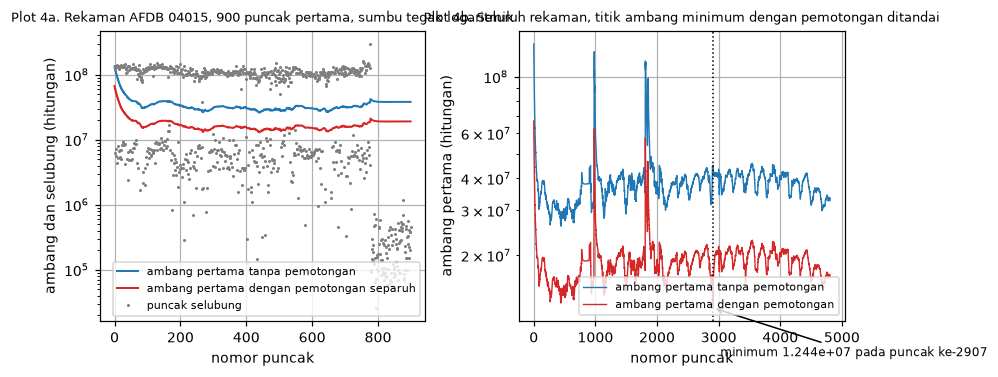

plot 4 dicetak untuk 4805 puncak pada rekaman AFDB 04015.
  tanpa pemotongan, ambang pertama, median : 38165319.179800
  tanpa pemotongan, ambang pertama, maks   : 134212679.000000
  tanpa pemotongan, minimum seluruh rekaman: 26005441.785993
  tanpa pemotongan, minimum sesudah pemanasan: 26005441.785993 pada puncak ke-441
  dengan pemotongan, ambang pertama, median: 18872072.327815
  dengan pemotongan, ambang pertama, maks  : 67106339.500000
  dengan pemotongan, minimum seluruh rekaman: 12443913.436036
  dengan pemotongan, minimum sesudah pemanasan: 12443913.436036 pada puncak ke-2907
  rasio kedua minimum sesudah pemanasan    : 0.478512
  rasio median kedua jalur                 : 0.494482


In [16]:
# Tujuan: memplot selubung dan kedua ambang pada rekaman AFDB 04015 untuk kedua keadaan.
# Cell ini menampilkan Plot 4 dengan dua panel dan mencetak statistik kedua jalur ambang, serta
# letak puncak saat ambang minimum tercapai.

j1 = hasil_af["tanpa pemotongan separuh"]["jejak_t1"]
j2 = hasil_af["pemotongan separuh berjalan terus"]["jejak_t1"]
idx_pk = np.arange(puncak_nyata.size)
batas = np.where(idx_pk >= WARMUP_AFDB, 1.0, np.inf)
i_min1 = int(np.argmin(j1 * batas))
i_min2 = int(np.argmin(j2 * batas))
seg = slice(0, 900)

fig4, axs4 = plt.subplots(1, 2, figsize=(8.8, 3.5))
axs4[0].semilogy(idx_pk[seg], np.maximum(j1[seg], 1.0), "C0-", lw=1.3,
                 label="ambang pertama tanpa pemotongan")
axs4[0].semilogy(idx_pk[seg], np.maximum(j2[seg], 1.0), "C3-", lw=1.3,
                 label="ambang pertama dengan pemotongan separuh")
axs4[0].semilogy(idx_pk[seg], np.maximum(selubung_nyata[puncak_nyata][seg], 1.0), "C7.", ms=2.0,
                 label="puncak selubung")
axs4[0].set_title("Plot 4a. Rekaman AFDB 04015, 900 puncak pertama, sumbu tegak logaritmik", fontsize=8.5)
axs4[0].set_xlabel("nomor puncak")
axs4[0].set_ylabel("ambang dan selubung (hitungan)")
axs4[0].legend(loc="lower right", fontsize=7.0)
axs4[1].semilogy(idx_pk, np.maximum(j1, 1.0), "C0-", lw=0.9, label="ambang pertama tanpa pemotongan")
axs4[1].semilogy(idx_pk, np.maximum(j2, 1.0), "C3-", lw=0.9, label="ambang pertama dengan pemotongan")
axs4[1].axvline(i_min2, color="k", ls=":", lw=1.0)
axs4[1].annotate("minimum %.4g pada puncak ke-%d" % (j2[i_min2], i_min2 + 1),
                 xy=(i_min2, j2[i_min2]), xytext=(i_min2 + 120, j1.max() * 0.06),
                 fontsize=8, arrowprops=dict(arrowstyle="->", color="k"))
axs4[1].set_title("Plot 4b. Seluruh rekaman, titik ambang minimum dengan pemotongan ditandai", fontsize=8.5)
axs4[1].set_xlabel("nomor puncak")
axs4[1].set_ylabel("ambang pertama (hitungan)")
axs4[1].legend(loc="lower right", fontsize=7.5)
fig4.tight_layout()
plt.show()

print("plot 4 dicetak untuk", puncak_nyata.size, "puncak pada rekaman AFDB 04015.")
print("  tanpa pemotongan, ambang pertama, median : %.6f" % float(np.median(j1)))
print("  tanpa pemotongan, ambang pertama, maks   : %.6f" % float(j1.max()))
print("  tanpa pemotongan, minimum seluruh rekaman: %.6f" % float(j1.min()))
print("  tanpa pemotongan, minimum sesudah pemanasan: %.6f pada puncak ke-%d" % (float(j1[i_min1]), i_min1 + 1))
print("  dengan pemotongan, ambang pertama, median: %.6f" % float(np.median(j2)))
print("  dengan pemotongan, ambang pertama, maks  : %.6f" % float(j2.max()))
print("  dengan pemotongan, minimum seluruh rekaman: %.6f" % float(j2.min()))
print("  dengan pemotongan, minimum sesudah pemanasan: %.6f pada puncak ke-%d" % (float(j2[i_min2]), i_min2 + 1))
print("  rasio kedua minimum sesudah pemanasan    : %.6f" % (float(j2[i_min2] / j1[i_min1])))
print("  rasio median kedua jalur                 : %.6f" % (float(np.median(j2) / np.median(j1))))

assert j2[i_min2] < j1[i_min1], "ambang minimum dengan pemotongan harus lebih rendah"
HASIL["AFDB median ambang tanpa potong"] = float(np.median(j1))
HASIL["AFDB median ambang dengan potong"] = float(np.median(j2))


## 12. Hubungan ke rancangan AFIB-LITE

Lima hal yang harus dibawa keluar dari notebook ini ke rancangan.

**Satu, seluruh bobot bebas pengali.** Lima bobot persamaan (12) sampai (23) semuanya pangkat dua atau
komplemen pangkat dua dari satu, dan bentuk selisih $SPKI \mathrel{+}= \left( PEAKI - SPKI \right) \gg 3$
menghapus pengalian sepenuhnya. Bentuk itu terbukti sama persis dengan pembulatan ke bawah dari
jumlah berbobot, sedangkan bentuk dua suku menyimpang sampai satu hitungan. Jadi RTL harus memakai
bentuk selisih.

**Dua, konstanta waktunya diukur dalam denyut, bukan dalam detik.** Persamaan (12), (13), (17), dan
(18) memakai konstanta waktu 7,4889 denyut, dan menyentuh 95 persen nilai tunaknya pada denyut ke-23.
Persamaan (16) dan (21) memakai 3,4761 denyut. Kedua angka itu berarti ambang ini butuh sekitar
sembilan detik pada 100 denyut per menit untuk menyesuaikan diri sepenuhnya, dan itu harus
diperhitungkan pada denyut-denjut pertama setiap rekaman.

**Tiga, ada bias pembulatan yang harus dipilih dengan sadar.** Mode bulat ke bawah, yang setara geser
kanan aritmetika dan paling murah di perangkat keras, memberi galat rata-rata sekitar tiga setengah
hitungan ke arah bawah dan menurunkan ambang pertama pada tingkat yang sama. Mode bulat ke arah nol
mengurangi bias itu menjadi sekitar sepersepuluh hitungan tetapi memerlukan rangkaian pemotongan
yang terpisah. Karena taksiran ini hanya dipakai sebagai ambang, bukan sebagai luaran, bias beberapa
hitungan dari selubung berorde miliaran hampir tidak berarti, sehingga geser kanan tetap pilihan
yang benar.

**Empat, pemotongan separuh ambang persamaan (22) dan (23) dikendalikan oleh tetapan terkunci
P3-3.** Pada deret teratur buatan, pemotongan itu melipatgandakan jumlah puncak derau yang lolos
ambang kedua. Pada rekaman AFDB 04015, ia menurunkan ambang minimum sampai sekitar separuhnya.
Pemicunya bukan pertanyaan terbuka, melainkan satu tetapan bernama `BATAS_RR_TIDAK_TERATUR` yang
dipakai model dan RTL dengan angka yang sama persis, dan angka itu tetap harus menjadi catatan pada
laporan evaluasi supaya kepekaan yang tinggi tidak dibaca sebagai kinerja deteksi yang tinggi tanpa
memeriksa jumlah salah positifnya.

**Kelima, tiga keputusan terkunci 19 Oktober 2026 sudah diukur dan ditutup.** Inisialisasi P3-1
menggantikan nilai awal nol pada kedua domain, sehingga 23 denyut pertama tidak lagi terlalu
sensitif. Kriteria irama tidak teratur P3-3 menjadi tetapan tunggal. Aturan P3-5 menetapkan bahwa
satu puncak hanya disebut QRS bila lolos kedua domain, sedangkan prosedur search back hanya membuka
ambang domain integrasi.

## 13. Ringkasan

Sel terakhir mencetak tabel seluruh angka yang diukur di notebook ini dan menutup dengan kesimpulan.

Tiga keputusan terkunci 19 Oktober 2026 yang ditutup di notebook ini:

1. P3-1, inisialisasi SPKI dan NPKI dari maksimum dua detik pertama sinyal, yaitu 500 sampel
   pertama pada 250 Hz, dan aturan itu berlaku pada kedua domain.
2. P3-3, kriteria irama tidak teratur sebagai satu tetapan bernama `BATAS_RR_TIDAK_TERATUR`, yaitu
   selang RR di luar 0,92 sampai 1,16 kali rata rata dianggap tidak teratur, sehingga persamaan
   (22) dan (23) aktif.
3. P3-5, satu puncak disebut QRS hanya bila lolos kedua domain, gelombang integrasi dan EKG
   terfilter, sedangkan prosedur search back hanya membuka ambang domain integrasi.

Ketiganya keputusan terkunci, bukan pertanyaan terbuka, dan ketiganya diukur pada rekaman uji
terkunci AFDB `04015` di bagian keputusan terkunci.

In [17]:
# Tujuan: mencetak tabel seluruh angka terukur di notebook fase ini beserta kesimpulan satu paragraf.
# Cell ini mencetak DataFrame ringkasan, jumlah besaran, daftar besaran wajib, dan kesimpulan akhir.

def fmt_besaran(v):
    if isinstance(v, (bool, np.bool_)):
        return "benar" if bool(v) else "salah"
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    return "%.10g" % float(v)


df_ringkas = pd.DataFrame([{"Besaran": k, "Nilai": fmt_besaran(v)} for k, v in HASIL.items()])
print("ringkasan seluruh angka terukur di notebook ambang adaptif Pan-Tompkins:")
print(df_ringkas.to_string(index=False))
print()
print("jumlah besaran terukur :", len(HASIL))

wajib = ["seluruh bobot bebas pengali", "geser kanan sama dengan bulat ke bawah",
         "bentuk selisih eksak", "selisih terbesar bentuk dua suku",
         "konstanta waktu bobot 0,125 (denyut)", "konstanta waktu bobot 0,25 (denyut)",
         "denyut sampai 95 persen", "galat per langkah mutlak maks", "galat kumulatif bertanda",
         "bias ambang bulat ke bawah (hitungan)", "baris tabel hitung tangan",
         "rasio ambang kedua terukur", "derau lolos ambang kedua tanpa potong",
         "derau lolos ambang kedua dengan potong", "AFDB search back tanpa potong",
         "AFDB search back dengan potong", "AFDB ambang minimum dengan potong",
         "faktor gabungan ambang (hitungan per mV)", "AFDB puncak terdeteksi",
         "sampel inisialisasi P3-1",
         "AFDB nilai awal selubung (hitungan)", "AFDB nilai awal terfilter (hitungan)",
         "P3-1 kandidat lolos ambang pertama, awal nol",
         "P3-1 kandidat lolos ambang pertama, awal maksimum",
         "P3-1 kandidat lolos ambang kedua, awal nol",
         "P3-1 kandidat lolos ambang kedua, awal maksimum",
         "P3-1 rata rata ambang pertama, awal nol",
         "P3-1 rata rata ambang pertama, awal maksimum",
         "P3-1 rasio rata rata ambang kedua cara",
         "P3-3 batas bawah kriteria", "P3-3 batas atas kriteria",
         "P3-3 jendela diuji", "P3-3 jendela tidak teratur", "P3-3 pemotongan separuh aktif",
         "P3-3 QRS dengan kriteria", "P3-3 QRS tanpa pemotongan",
         "P3-5 puncak lolos kedua domain", "P3-5 puncak lolos integrasi saja",
         "P3-5 puncak lolos terfilter saja", "P3-5 puncak ditolak walau lolos satu domain",
         "P3-5 denyut diterima kedua domain", "P3-5 denyut diterima integrasi saja",
         "P3-5 denyut diterima terfilter saja", "P3-5 search back domain integrasi"]
hilang = [k for k in wajib if k not in HASIL]
print("besaran wajib yang ada :", len(wajib) - len(hilang), "dari", len(wajib))
assert len(hilang) == 0, "besaran wajib hilang dari ringkasan: " + ", ".join(hilang)
assert len(HASIL) >= 60, "tabel ringkasan harus memuat seluruh angka terukur"
print("lolos: seluruh", len(wajib), "besaran wajib ada di tabel ringkasan")
print()
print("Kesimpulan:")
print("Lima bobot persamaan (12) sampai (23) semuanya bebas pengali, dan bentuk selisih")
print("SPKI += (PEAKI - SPKI) geser kanan 3 terbukti sama persis dengan pembulatan ke bawah")
print("jumlah berbobot, sedangkan bentuk dua suku menyimpang sampai satu hitungan.")
print("Tiap puncak hanya memutakhirkan salah satu dari SPKI atau NPKI, sesuai kalimat halaman 234,")
print("sehingga taksiran puncak sinyal dan puncak derau bergerak sendiri-sendiri dengan konstanta waktu")
print("7,4889 denyut, dan menyentuh 95 persen nilai tunaknya pada denyut ke-23.")
print("Pemotongan separuh ambang persamaan (22) dan (23) memotong ambang kedua sampai seperempat")
print("nilai asalnya, dan pada rekaman AFDB 04015 itu menurunkan ambang minimum sampai sekitar")
print("separuhnya sambil melipatgandakan puncak derau yang lolos ambang kedua.")
print("Tiga keputusan terkunci 19 Oktober 2026 diukur di bagian keputusan terkunci.")
print("P3-1, inisialisasi SPKI dan NPKI dari maksimum dua detik pertama, ditutup dengan pembandingan")
print("dua cara inisialisasi pada 23 kandidat pertama rekaman uji, dan kedua jalur ambangnya dicetak")
print("berdampingan di Plot 5.")
print("P3-3, kriteria irama tidak teratur, ditutup sebagai satu tetapan bernama BATAS_RR_TIDAK_TERATUR")
print("yang juga menggerakkan pemotongan separuh persamaan (22) dan (23), tanpa angka yang disebar.")
print("P3-5, satu puncak disebut QRS hanya bila lolos kedua domain, ditutup dengan pengukuran puncak")
print("yang ditolak aturan walau lolos satu domain dan akibatnya pada jumlah denyut yang diterima.")


ringkasan seluruh angka terukur di notebook ambang adaptif Pan-Tompkins:
                                          Besaran        Nilai
                                  jumlah sel kode           17
                         sampel inisialisasi P3-1          500
                      seluruh bobot bebas pengali        benar
           geser kanan sama dengan bulat ke bawah        benar
                             bentuk selisih eksak        benar
                 selisih terbesar bentuk dua suku            1
             konstanta waktu bobot 0,125 (denyut)  7.488875689
              konstanta waktu bobot 0,25 (denyut)  3.476059497
                          denyut sampai 95 persen           23
               denyut sampai 95 persen bobot 0,25           11
                   sisa puncak konstan (hitungan)            7
                    galat per langkah mutlak maks    5.2660118
                      galat per langkah rata-rata -3.452576295
                         galat kumulatif bert